# 1. Cài đặt môi trường

In [ ]:
!pip -q install transformers accelerate gradio gdown emoji wordcloud

In [ ]:
import os, re, json, html, random, pickle, gc, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 140)

# ---- Thư mục làm việc (lưu vào Google Drive để không mất kết quả khi Colab ngắt) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/DO_AN_XLNNTN")
except Exception:
    WORK = Path("./pstance_project")
for sub in ["data", "results", "models", "outputs"]:
    (WORK / sub).mkdir(parents=True, exist_ok=True)
DATA_DIR, RES_DIR, MODEL_DIR, OUT_DIR = WORK/"data", WORK/"results", WORK/"models", WORK/"outputs"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "KHÔNG có GPU -> vào Runtime > Change runtime type > T4 GPU")
print("Torch:", torch.__version__)

Mounted at /content/drive
Device: cuda | Tesla T4
Torch: 2.11.0+cu130


In [ ]:
# =====================  CẤU HÌNH TOÀN ĐỀ TÀI  =====================
QUICK_MODE = False          # True = chạy thử nhanh (10% dữ liệu, 1 epoch)

TARGETS     = ["trump", "biden", "bernie"]
TARGET_NAME = {"trump": "Donald Trump", "biden": "Joe Biden", "bernie": "Bernie Sanders"}
LABEL2ID    = {"AGAINST": 0, "FAVOR": 1}
ID2LABEL    = {0: "AGAINST", 1: "FAVOR"}

# ---- Siêu tham số fine-tune: lấy theo bài báo P-Stance (Mục 4.3 & README repo) ----
MAX_LEN = 128      # bài báo: maximum sequence length = 128
BATCH   = 32       # bài báo: batch size = 32
LR      = 2e-5     # bài báo: AdamW, learning rate = 2e-5
EPOCHS  = 3        # README của repo chính thức: --epochs 3
WD      = 0.01     # weight decay (mặc định AdamW của BERT; bài báo không nêu)
WARMUP  = 0.1      # warm-up 10% số bước (không nêu trong bài báo -> chọn phổ biến)
SEEDS   = [42, 123, 2024]   # đồ án yêu cầu >= 3 seed, báo cáo mean ± std (bài báo dùng 7 lần chạy)

# ---- 3 kiến trúc pretrained (bảng gợi ý của đề cương cho văn bản tiếng Anh) ----
MODELS = {
    "BERT-base":    "bert-base-uncased",
    "RoBERTa-base": "roberta-base",
    "DistilBERT":   "distilbert-base-uncased",
}
CROSS_MODELS = ["BERT-base"]   # cross-target bắt buộc với BERT; thêm "RoBERTa-base", "DistilBERT" nếu còn thời gian GPU

if QUICK_MODE:
    EPOCHS = 1

# Từ khóa nhận diện nhắc tới nhân vật (dùng cho EDA + phân tích lỗi)
KEYWORDS = {
    "trump":  ["trump", "donald", "potus", "maga"],
    "biden":  ["biden", "sleepy joe", "joebiden"],
    "bernie": ["bernie", "sanders", "feelthebern"],
}

# Số liệu tham chiếu từ bài báo (để đối chiếu)
PAPER_TABLE6 = {   # (train FAVOR, AGAINST), (val), (test)
    "trump":  {"train": (2937, 3425), "val": (365, 430), "test": (361, 435)},
    "biden":  {"train": (2552, 3254), "val": (328, 417), "test": (337, 408)},
    "bernie": {"train": (2858, 2198), "val": (350, 284), "test": (343, 292)},
}
PAPER_INTARGET = {   # Bảng 9: Macro-F1 (%) - Ad-hoc & Merged
    "[Bài báo] BERT ad-hoc":      {"trump": 78.28, "biden": 78.70, "bernie": 72.45, "Fmacro": 76.48},
    "[Bài báo] BERT merged":      {"trump": 79.19, "biden": 76.02, "bernie": 73.59, "Fmacro": 76.27},
    "[Bài báo] BERTweet merged":  {"trump": 83.81, "biden": 79.08, "bernie": 77.75, "Fmacro": 80.21},
}
PAPER_CROSS = {      # Bảng 10: huấn luyện trên 2 mục tiêu, test trên mục tiêu còn lại (held-out)
    "[Bài báo] BiCE":      {"bernie": 52.26, "biden": 53.73, "trump": 53.91},
    "[Bài báo] CrossNet":  {"bernie": 56.26, "biden": 55.57, "trump": 56.44},
    "[Bài báo] BERTweet":  {"bernie": 69.99, "biden": 68.64, "trump": 66.01},
}

print(pd.DataFrame({
    "Tham số": ["max_len", "batch_size", "optimizer", "learning_rate", "epochs", "weight_decay", "warmup", "seeds", "kiến trúc"],
    "Giá trị": [MAX_LEN, BATCH, "AdamW", LR, EPOCHS, WD, WARMUP, SEEDS, list(MODELS)],
    "Nguồn": ["Bài báo §4.3", "Bài báo §4.3", "Bài báo §4.3", "Bài báo §4.3", "README repo chính thức",
              "Mặc định BERT", "Chọn thêm", "Đề cương (≥3 seed)", "Đề cương"],
}).to_string(index=False))

      Tham số                               Giá trị                  Nguồn
      max_len                                   128           Bài báo §4.3
   batch_size                                    32           Bài báo §4.3
    optimizer                                 AdamW           Bài báo §4.3
learning_rate                               0.00002           Bài báo §4.3
       epochs                                     3 README repo chính thức
 weight_decay                                  0.01          Mặc định BERT
       warmup                                   0.1              Chọn thêm
        seeds                       [42, 123, 2024]     Đề cương (≥3 seed)
    kiến trúc [BERT-base, RoBERTa-base, DistilBERT]               Đề cương


In [ ]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix, accuracy_score

def f1m(y, p):
    # Macro-F1 trên 2 lớp = (F_favor + F_against)/2 = F_avg trong bài báo (công thức 1-3)
    return f1_score(y, p, average="macro")

def per_target_scores(df_, pred):
    # Macro-F1 (%) theo từng mục tiêu + Fmacro (trung bình các mục tiêu có trong df_)
    out = {}
    for t in TARGETS:
        m = (df_.target.values == t)
        if m.sum():
            out[t] = f1m(df_.label.values[m], np.asarray(pred)[m]) * 100
    out["Fmacro"] = float(np.mean([out[t] for t in TARGETS if t in out]))
    return out

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 2. Nạp dữ liệu

P-Stance được tác giả phát hành trên Google Drive (link trong README của repo `chuchun8/PStance`).
Mỗi mục tiêu có 3 file: `raw_train_<target>.csv`, `raw_val_<target>.csv`, `raw_test_<target>.csv` với `<target>` ∈ {trump, biden, bernie}; chia **80/10/10** theo bài báo.

> Nếu `gdown` tải thất bại (Drive giới hạn lượt tải), hãy tải thủ công thư mục từ README của repo và đưa **9 file csv** vào thư mục `pstance_project/data` trên Drive của bạn, rồi chạy lại ô nạp dữ liệu.

In [ ]:
import gdown
PSTANCE_FOLDER = "https://drive.google.com/drive/folders/1so8lY1XKpnhUtTvb15edEz6aeHt7CSuh"

def have_all_files():
    names = {p.name.lower() for p in DATA_DIR.rglob("*.csv")}
    return all(f"raw_{s}_{t}.csv" in names for s in ["train", "val", "test"] for t in TARGETS)

if not have_all_files():
    try:
        gdown.download_folder(url=PSTANCE_FOLDER, output=str(DATA_DIR), quiet=True, use_cookies=False)
    except Exception as e:
        print("gdown lỗi:", e)
if not have_all_files():
    raise FileNotFoundError("Chưa đủ 9 file raw_{train,val,test}_{trump,biden,bernie}.csv trong " + str(DATA_DIR)
                            + " -> tải thủ công từ README repo chuchun8/PStance rồi chạy lại.")
print("Các file dữ liệu:", sorted(p.name for p in DATA_DIR.rglob("*.csv")))

Các file dữ liệu: ['raw_test_bernie.csv', 'raw_test_biden.csv', 'raw_test_trump.csv', 'raw_train_bernie.csv', 'raw_train_biden.csv', 'raw_train_trump.csv', 'raw_val_bernie.csv', 'raw_val_biden.csv', 'raw_val_trump.csv']


In [ ]:
def find_file(split, t):
    return next(p for p in DATA_DIR.rglob("*.csv") if p.name.lower() == f"raw_{split}_{t}.csv")

frames = []
for split in ["train", "val", "test"]:
    for t in TARGETS:
        d = pd.read_csv(find_file(split, t))
        d.columns = [c.strip().lower() for c in d.columns]
        if "target" in d.columns:
            d = d.rename(columns={"target": "target_raw"})
        tcol = next(c for c in ["tweet", "text"] if c in d.columns)
        d = d.rename(columns={tcol: "text"})
        d["target"], d["split"] = t, split
        frames.append(d)
df = pd.concat(frames, ignore_index=True)
df["stance"] = df["stance"].astype(str).str.strip().str.upper()
df = df[df.stance.isin(["FAVOR", "AGAINST"])].copy()
df["text"] = df["text"].astype(str)
df["target_name"] = df.target.map(TARGET_NAME)
df["label"] = df.stance.map(LABEL2ID)

if QUICK_MODE:   # chạy thử nhanh
    df = df.groupby(["split", "target"], group_keys=False).sample(frac=0.10, random_state=0)
df = df.reset_index(drop=True)

print("Cột:", list(df.columns))
print("Tổng số tweet:", len(df))
display(df[["text", "target_name", "stance", "split"]].sample(6, random_state=1))

Cột: ['text', 'target_raw', 'stance', 'target', 'split', 'target_name', 'label']
Tổng số tweet: 21574


,text,target_name,stance,split
14473,Yes. Its nauseating to see her licking #BernieSanders boots. She should be a strong women and not a yes-women.,Bernie Sanders,AGAINST,train
8976,TY @JoeBiden for standing by @SenKamalaHarris. I block &amp; report any suspicious attempts (foreign or domestic) on social media to onc...,Joe Biden,FAVOR,train
13257,"""awr"" isn't that cute this 14 day old twitter account has tweeted almost 100 tweets per day The opposition to Bernie is Fake. #FakeTwitt...",Bernie Sanders,FAVOR,train
275,.@realDonaldTrump Thursday strategy is to throw everything and the kitchen sink at the #MuellerStatement to distract the media and Ameri...,Donald Trump,AGAINST,train
19981,Thank you... I hope there are no hard feelings. I just could not stomach you as #Potus so I helped the other guy. Ye vay. Did I screw th...,Donald Trump,AGAINST,test
9638,I've enjoyed every single day of it. The good ones and the bad ones. - John McCain on his life of service McCain is pictured with @JoeBi...,Joe Biden,FAVOR,train


In [ ]:
# ---- Đối chiếu số liệu với Bảng 6 của bài báo ----
cnt = df.groupby(["target", "split", "stance"]).size().unstack("stance", fill_value=0)
rows = []
for t in TARGETS:
    for s in ["train", "val", "test"]:
        pf, pa = PAPER_TABLE6[t][s]
        of, oa = int(cnt.loc[(t, s), "FAVOR"]), int(cnt.loc[(t, s), "AGAINST"])
        rows.append({"Mục tiêu": TARGET_NAME[t], "Tập": s, "FAVOR (bài báo)": pf, "FAVOR (tải về)": of,
                     "AGAINST (bài báo)": pa, "AGAINST (tải về)": oa,
                     "Khớp": (pf == of and pa == oa) or QUICK_MODE})
chk = pd.DataFrame(rows)
display(chk)
print("Tổng theo bài báo: Trump 7953 | Biden 7296 | Sanders 6325 = 21.574")
print("Khớp hoàn toàn Bảng 6:", bool(chk["Khớp"].all()))

# tập dùng xuyên suốt notebook
tr_all = df[df.split == "train"].reset_index(drop=True)
va_all = df[df.split == "val"].reset_index(drop=True)
te_all = df[df.split == "test"].reset_index(drop=True)
print(f"train={len(tr_all)} | val={len(va_all)} | test={len(te_all)}")

,Mục tiêu,Tập,FAVOR (bài báo),FAVOR (tải về),AGAINST (bài báo),AGAINST (tải về),Khớp
0,Donald Trump,train,2937,2937,3425,3425,True
1,Donald Trump,val,365,374,430,440,False
2,Donald Trump,test,361,352,435,425,False
3,Joe Biden,train,2552,2552,3254,3254,True
4,Joe Biden,val,328,328,417,417,True
5,Joe Biden,test,337,337,408,408,True
6,Bernie Sanders,train,2858,2858,2198,2198,True
7,Bernie Sanders,val,350,350,284,284,True
8,Bernie Sanders,test,343,343,292,292,True


Tổng theo bài báo: Trump 7953 | Biden 7296 | Sanders 6325 = 21.574
Khớp hoàn toàn Bảng 6: False
train=17224 | val=2193 | test=2157


# 3. Phân tích khám phá dữ liệu (EDA)

### 3.1 Phân bố nhãn theo mục tiêu và theo tập train/val/test
Mục đích: kiểm tra mất cân bằng lớp (ảnh hưởng đến lựa chọn thang đo → dùng **Macro-F1** thay vì Accuracy) và kiểm tra chia tập có giữ tỉ lệ nhãn hay không.

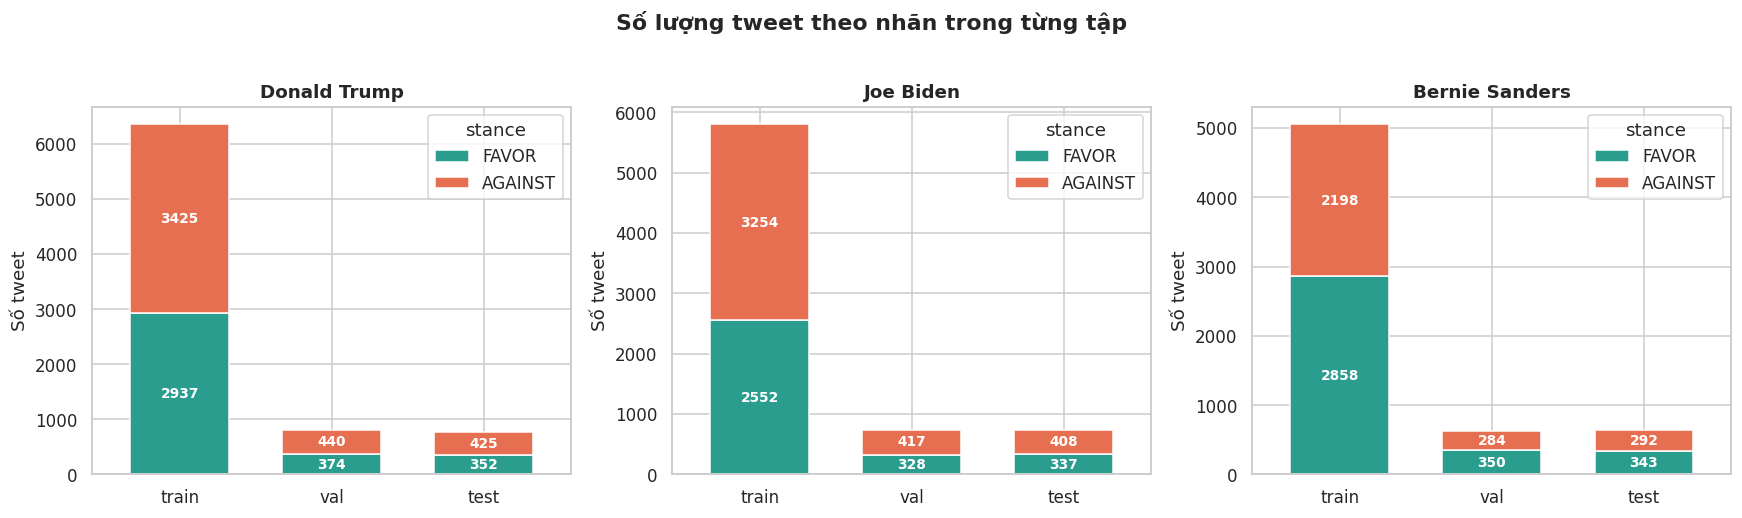

Tỉ lệ FAVOR (%) theo mục tiêu / tập (50% = cân bằng):


split,train,val,test,Toàn bộ
target_name,,,,
Bernie Sanders,56.5,55.2,54.0,56.1
Donald Trump,46.2,45.9,45.3,46.1
Joe Biden,44.0,44.0,45.2,44.1


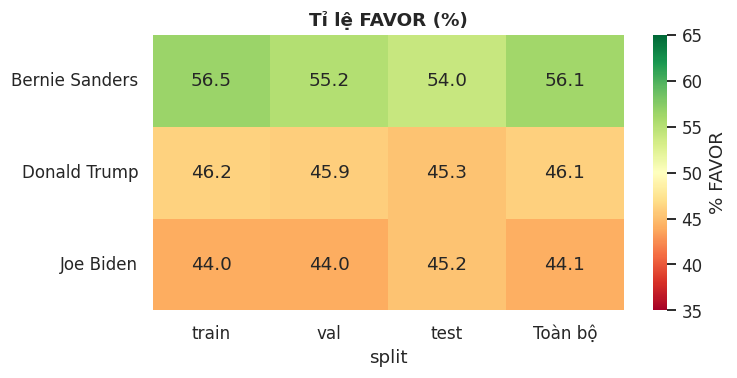

In [ ]:
PAL = {"FAVOR": "#2a9d8f", "AGAINST": "#e76f51"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, t in zip(axes, TARGETS):
    ct = df[df.target == t].groupby(["split", "stance"]).size().unstack(fill_value=0).reindex(["train", "val", "test"])
    ct[["FAVOR", "AGAINST"]].plot(kind="bar", stacked=True, ax=ax, color=[PAL["FAVOR"], PAL["AGAINST"]], rot=0, width=.65)
    for c in ax.containers:
        ax.bar_label(c, label_type="center", color="white", fontsize=9, fontweight="bold")
    ax.set_title(TARGET_NAME[t]); ax.set_xlabel(""); ax.set_ylabel("Số tweet")
plt.suptitle("Số lượng tweet theo nhãn trong từng tập", y=1.02, fontweight="bold"); plt.tight_layout(); plt.show()

# tỉ lệ FAVOR
ratio = (df.groupby(["target_name", "split"]).label.mean().unstack()[["train", "val", "test"]] * 100).round(1)
ratio["Toàn bộ"] = (df.groupby("target_name").label.mean() * 100).round(1)
print("Tỉ lệ FAVOR (%) theo mục tiêu / tập (50% = cân bằng):")
display(ratio)

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(ratio, annot=True, fmt=".1f", cmap="RdYlGn", center=50, vmin=35, vmax=65, ax=ax, cbar_kws={"label": "% FAVOR"})
ax.set_title("Tỉ lệ FAVOR (%)"); ax.set_ylabel(""); plt.tight_layout(); plt.show()

### 3.2 Độ dài tweet
Bài báo nhấn mạnh P-Stance có tweet **dài hơn** các bộ cũ (trung bình **30 từ** so với 16-21 từ) nên khó hơn. Ta kiểm tra lại.

,count,mean,std,min,50%,95%,max
target_name,,,,,,,
Bernie Sanders,6325.0,30.7,11.5,9.0,30.0,49.0,68.0
Donald Trump,7953.0,30.0,10.9,10.0,30.0,47.0,58.0
Joe Biden,7296.0,28.7,11.7,9.0,27.0,48.0,59.0
TOÀN BỘ,21574.0,29.8,11.4,9.0,29.0,48.0,68.0


-> Độ dài trung bình toàn bộ = 29.8 từ (bài báo: ~30 từ; SemEval-2016: 17; Multi-target: 21; WT-WT: 16)


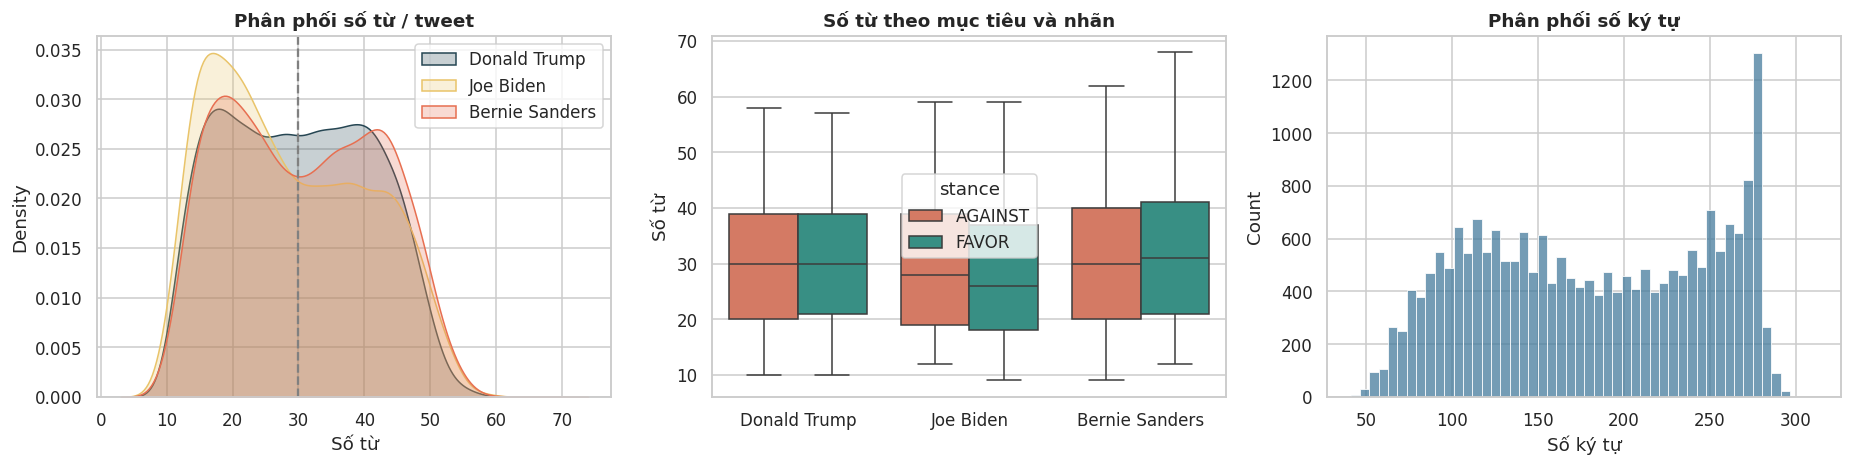

In [ ]:
df["n_words"] = df.text.str.split().str.len()
df["n_chars"] = df.text.str.len()

stats = df.groupby("target_name").n_words.describe(percentiles=[.5, .95])[["count", "mean", "std", "min", "50%", "95%", "max"]].round(1)
stats.loc["TOÀN BỘ"] = df.n_words.describe(percentiles=[.5, .95])[["count", "mean", "std", "min", "50%", "95%", "max"]].round(1)
display(stats)
print(f"-> Độ dài trung bình toàn bộ = {df.n_words.mean():.1f} từ (bài báo: ~30 từ; SemEval-2016: 17; Multi-target: 21; WT-WT: 16)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for t, c in zip(TARGETS, ["#264653", "#e9c46a", "#e76f51"]):
    sns.kdeplot(df[df.target == t].n_words, ax=axes[0], label=TARGET_NAME[t], fill=True, alpha=.25, color=c, clip=(0, 130))
axes[0].axvline(30, ls="--", c="gray"); axes[0].set_title("Phân phối số từ / tweet"); axes[0].set_xlabel("Số từ"); axes[0].legend()
sns.boxplot(data=df, x="target_name", y="n_words", hue="stance", palette=PAL, ax=axes[1], showfliers=False)
axes[1].set_title("Số từ theo mục tiêu và nhãn"); axes[1].set_xlabel(""); axes[1].set_ylabel("Số từ")
sns.histplot(df.n_chars, bins=50, ax=axes[2], color="#457b9d"); axes[2].set_title("Phân phối số ký tự"); axes[2].set_xlabel("Số ký tự")
plt.tight_layout(); plt.show()

### 3.3 Đặc trưng bề mặt của tweet: hashtag, mention, URL, emoji, dấu hỏi/chấm than

n_hashtag  n_mention  has_url  n_emoji  n_question  \
target_name    stance                                                        
Bernie Sanders AGAINST      2.026      0.437      0.0      0.0       0.340   
               FAVOR        1.516      0.305      0.0      0.0       0.221   
Donald Trump   AGAINST      2.160      0.402      0.0      0.0       0.290   
               FAVOR        2.905      0.820      0.0      0.0       0.214   
Joe Biden      AGAINST      1.300      0.410      0.0      0.0       0.381   
               FAVOR        1.643      0.949      0.0      0.0       0.182   

                        n_exclaim  n_upper_words  
target_name    stance                             
Bernie Sanders AGAINST      0.370          0.813  
               FAVOR        0.431          0.594  
Donald Trump   AGAINST      0.421          1.090  
               FAVOR        0.783          1.769  
Joe Biden      AGAINST      0.420          0.771  
               FAVOR        0.586          0.749

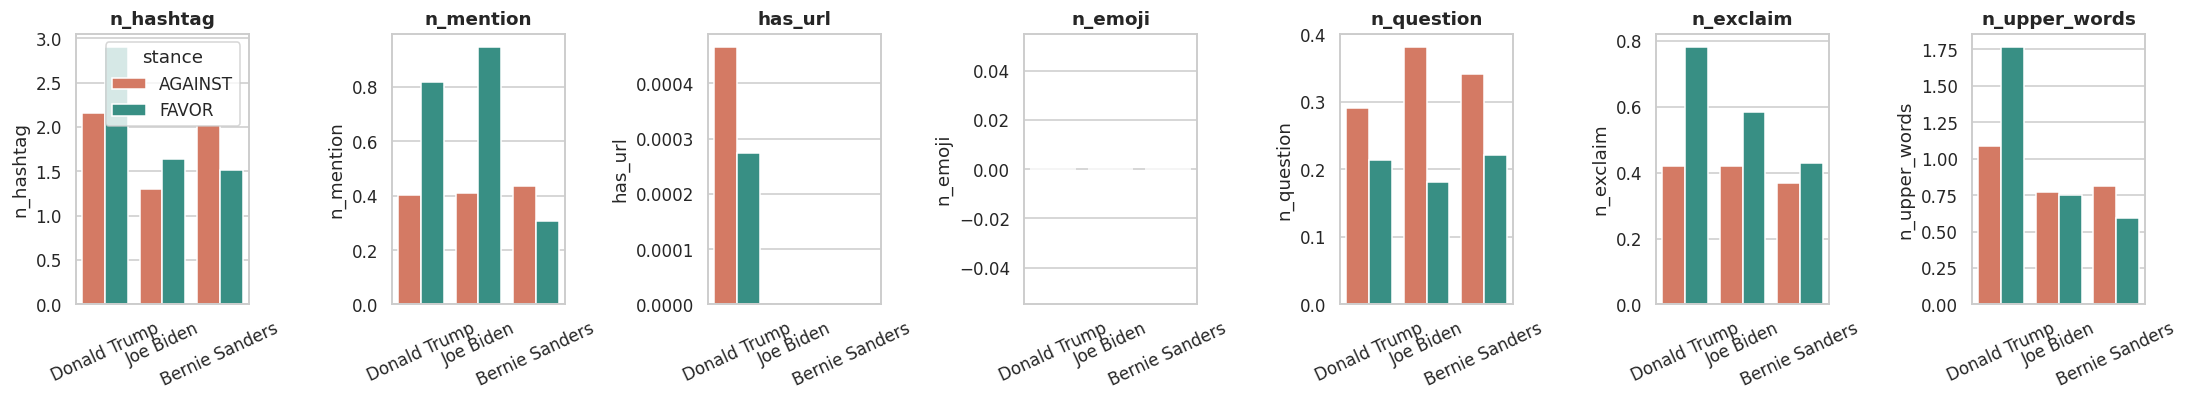

Tỉ lệ tweet có URL: 0.0% | có mention: 33.2% | có hashtag: 81.0%


In [ ]:
import emoji as emoji_lib
df["n_hashtag"] = df.text.str.count(r"#\w+")
df["n_mention"] = df.text.str.count(r"@\w+")
df["has_url"]   = df.text.str.contains(r"https?://|www\.", regex=True).astype(int)
df["n_emoji"]   = df.text.apply(lambda s: emoji_lib.emoji_count(s))
df["n_question"] = df.text.str.count(r"\?")
df["n_exclaim"]  = df.text.str.count("!")
df["n_upper_words"] = df.text.apply(lambda s: sum(w.isupper() and len(w) > 2 for w in s.split()))

feat = ["n_hashtag", "n_mention", "has_url", "n_emoji", "n_question", "n_exclaim", "n_upper_words"]
agg = df.groupby(["target_name", "stance"])[feat].mean().round(3)
display(agg)

fig, axes = plt.subplots(1, len(feat), figsize=(20, 3.8))
for ax, f in zip(axes, feat):
    sns.barplot(data=df, x="target_name", y=f, hue="stance", palette=PAL, ax=ax, errorbar=None)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
    if ax is not axes[0]: ax.get_legend().remove()
plt.tight_layout(); plt.show()
print("Tỉ lệ tweet có URL: %.1f%% | có mention: %.1f%% | có hashtag: %.1f%%" %
      (df.has_url.mean()*100, (df.n_mention > 0).mean()*100, (df.n_hashtag > 0).mean()*100))

### 3.4 Hashtag và từ khóa nổi bật theo từng mục tiêu × nhãn
> Bài báo đã **xóa các hashtag lộ lập trường** ở cuối câu (vd. `#NeverBernie`) nên hashtag còn lại chủ yếu là chủ đề/sự kiện.

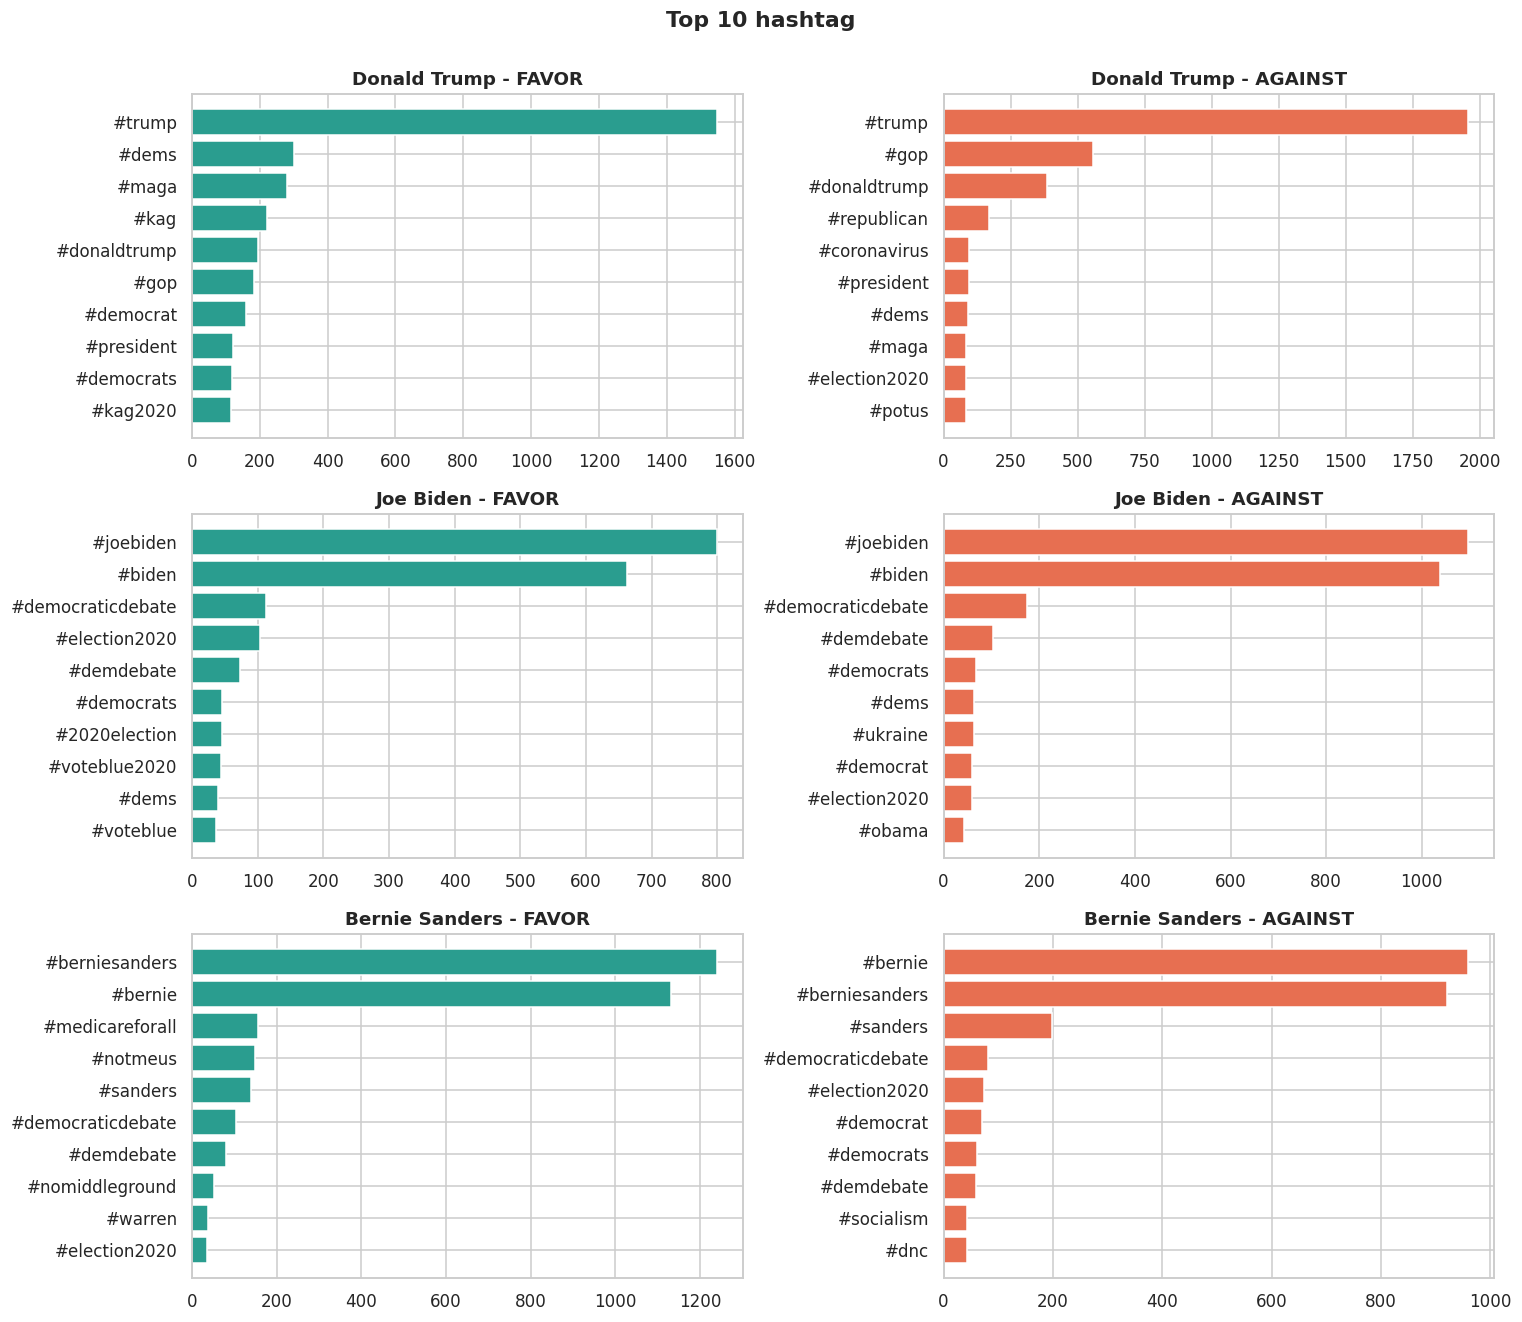

In [ ]:
from collections import Counter
def top_hashtags(texts, k=10):
    c = Counter(h.lower() for t in texts for h in re.findall(r"#\w+", t))
    return c.most_common(k)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for i, t in enumerate(TARGETS):
    for j, s in enumerate(["FAVOR", "AGAINST"]):
        items = top_hashtags(df[(df.target == t) & (df.stance == s)].text, 10)
        ax = axes[i, j]
        if items:
            names, vals = zip(*items[::-1])
            ax.barh(names, vals, color=PAL[s])
        ax.set_title(f"{TARGET_NAME[t]} - {s}")
plt.suptitle("Top 10 hashtag", y=1.0, fontweight="bold"); plt.tight_layout(); plt.show()

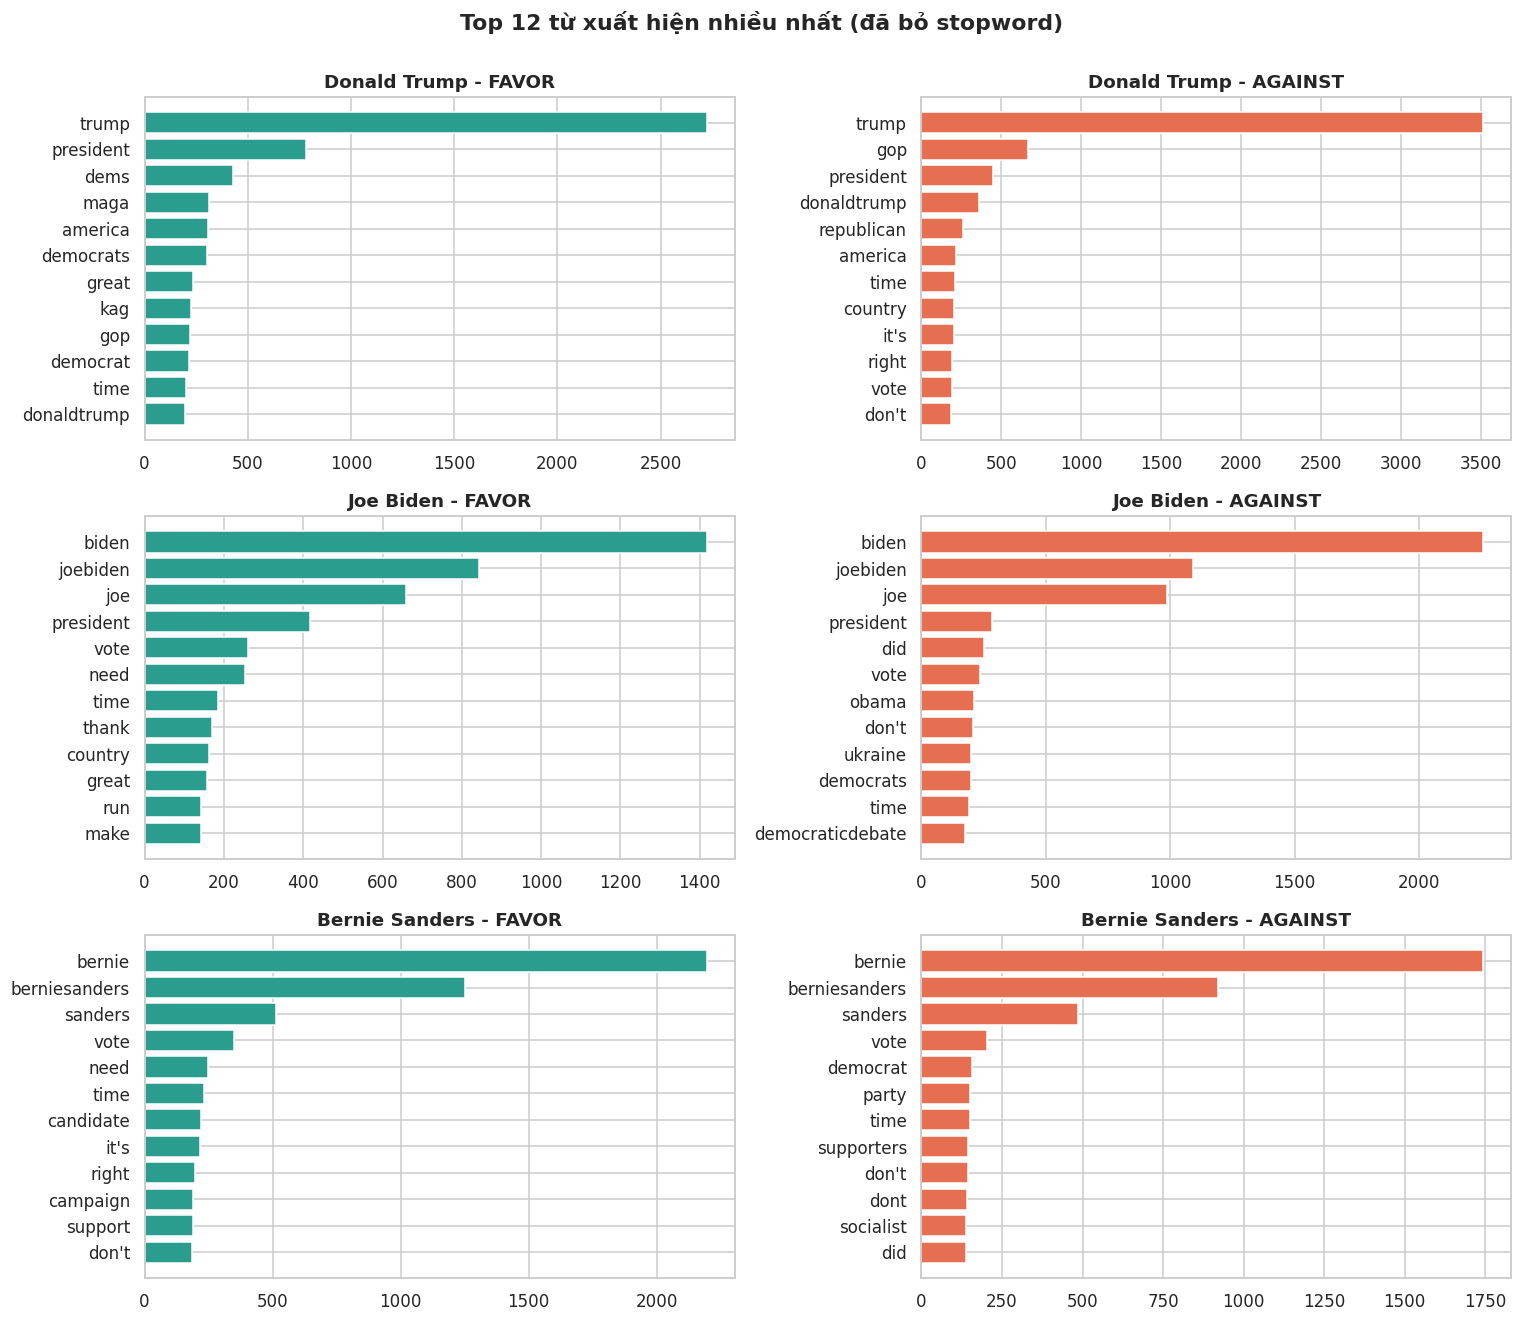

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
EXTRA_STOP = {"amp", "http", "https", "co", "just", "like", "people", "don", "ve", "ll", "know", "think", "going", "want", "say", "said", "https"}
STOP = list(ENGLISH_STOP_WORDS | EXTRA_STOP)

def eda_clean(s):
    s = re.sub(r"https?://\S+|www\.\S+", " ", s.lower())
    s = re.sub(r"@\w+|#", " ", s)
    return s

def top_words(texts, k=12):
    cv = CountVectorizer(stop_words=STOP, token_pattern=r"(?u)\b[a-z][a-z']{2,}\b", min_df=3)
    X = cv.fit_transform([eda_clean(x) for x in texts])
    freq = np.asarray(X.sum(0)).ravel()
    idx = freq.argsort()[::-1][:k]
    return [(cv.get_feature_names_out()[i], int(freq[i])) for i in idx]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for i, t in enumerate(TARGETS):
    for j, s in enumerate(["FAVOR", "AGAINST"]):
        items = top_words(df[(df.target == t) & (df.stance == s)].text, 12)
        names, vals = zip(*items[::-1])
        axes[i, j].barh(names, vals, color=PAL[s]); axes[i, j].set_title(f"{TARGET_NAME[t]} - {s}")
plt.suptitle("Top 12 từ xuất hiện nhiều nhất (đã bỏ stopword)", y=1.0, fontweight="bold"); plt.tight_layout(); plt.show()

### 3.5 Từ ngữ phân biệt FAVOR / AGAINST (log-odds)
Từ phổ biến chưa chắc là từ *phân biệt* lập trường. Dùng log-odds có làm mịn Dirichlet để tìm từ nghiêng về mỗi nhãn.

In [ ]:
def log_odds(texts_a, texts_b, k=10, alpha=0.5):
    cv = CountVectorizer(stop_words=STOP, token_pattern=r"(?u)\b[a-z][a-z']{2,}\b", min_df=5)
    X = cv.fit_transform([eda_clean(x) for x in list(texts_a) + list(texts_b)])
    na = len(texts_a)
    ca = np.asarray(X[:na].sum(0)).ravel() + alpha
    cb = np.asarray(X[na:].sum(0)).ravel() + alpha
    lo = np.log(ca / ca.sum()) - np.log(cb / cb.sum())
    vocab = cv.get_feature_names_out()
    order = lo.argsort()
    return [vocab[i] for i in order[::-1][:k]], [vocab[i] for i in order[:k]]

rows = []
for t in TARGETS:
    fav, ag = log_odds(df[(df.target == t) & (df.stance == "FAVOR")].text, df[(df.target == t) & (df.stance == "AGAINST")].text)
    rows.append({"Mục tiêu": TARGET_NAME[t], "Từ nghiêng về FAVOR": ", ".join(fav), "Từ nghiêng về AGAINST": ", ".join(ag)})
display(pd.DataFrame(rows))

,Mục tiêu,Từ nghiêng về FAVOR,Từ nghiêng về AGAINST
0,Donald Trump,"socialist, walkawayfromdemocrats, greatawakening, wattersworld, qanons, democratshateamerica, leftists, patriotsunited, patriots, bestpr...","donnie, fakepresident, donthecon, medicareforall, resigned, oversight, ego, racistinchief, kissing, mar"
1,Joe Biden,"iacaucus, birthday, fitn, rsvp, join, attending, resist, voteblue, presidentbiden, votejoe","creep, sleepyjoe, deals, girls, dementiajoe, crimes, cocaine, awful, innocent, feely"
2,Bernie Sanders,"volunteer, votebernie, grassroots, app, suffering, inspiration, solidarity, tomorrow, active, profits","jews, antifa, jew, jet, dictator, fidel, ussr, bread, hitler, tcot"


### 3.6 Từ vựng chung giữa các mục tiêu & việc nhắc tới nhân vật khác
Hai biểu đồ này liên quan trực tiếp tới **cross-target**: nếu từ vựng hai mục tiêu giống nhau (cùng đảng Dân chủ: Biden–Sanders) thì chuyển giao dễ hơn; nếu tweet về Trump nhắc nhiều tới Biden thì mô hình dễ nhầm mục tiêu.

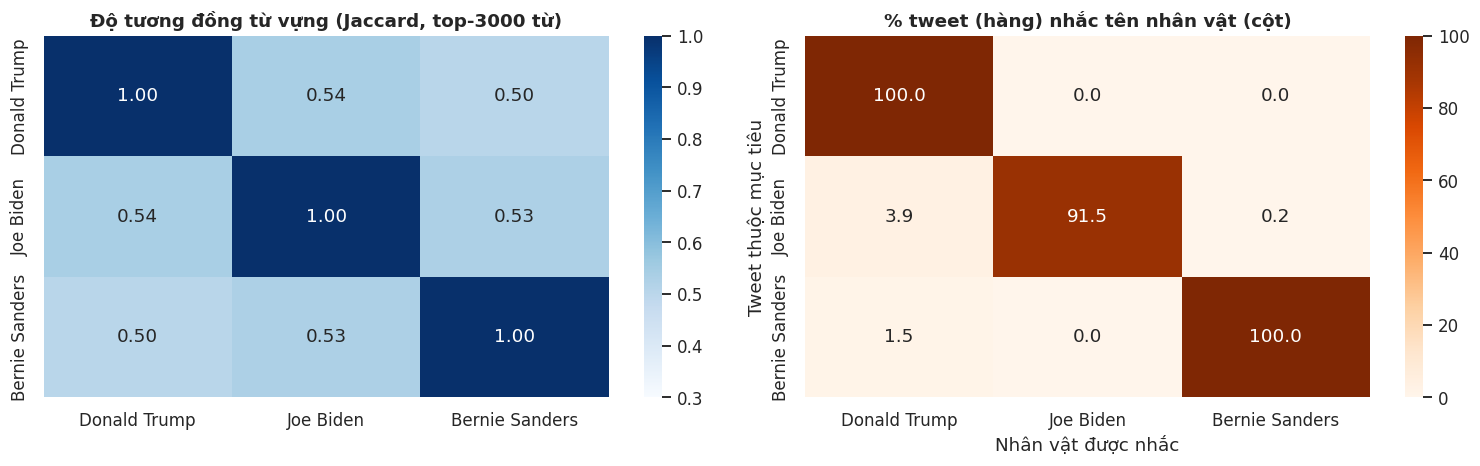

Tỉ lệ tweet nhắc TÊN mục tiêu của chính nó: {'Donald Trump': '100.0%', 'Joe Biden': '91.5%', 'Bernie Sanders': '100.0%'}
-> Phần còn lại là tweet nhắc mục tiêu một cách NGẦM (hashtag cuối câu đã bị xóa) – đúng đặc điểm 'implicit target' bài báo nêu.


In [ ]:
def vocab_top(texts, k=3000):
    cv = CountVectorizer(stop_words=STOP, token_pattern=r"(?u)\b[a-z][a-z']{2,}\b", min_df=3)
    X = cv.fit_transform([eda_clean(x) for x in texts])
    freq = np.asarray(X.sum(0)).ravel()
    return set(cv.get_feature_names_out()[freq.argsort()[::-1][:k]])

V = {t: vocab_top(df[df.target == t].text) for t in TARGETS}
J = pd.DataFrame([[len(V[a] & V[b]) / len(V[a] | V[b]) for b in TARGETS] for a in TARGETS],
                 index=[TARGET_NAME[t] for t in TARGETS], columns=[TARGET_NAME[t] for t in TARGETS])

def mention_share(texts, tgt):
    low = texts.str.lower()
    return low.apply(lambda s: any(k in s for k in KEYWORDS[tgt])).mean() * 100

M = pd.DataFrame({TARGET_NAME[m]: [mention_share(df[df.target == t].text, m) for t in TARGETS] for m in TARGETS},
                 index=[TARGET_NAME[t] for t in TARGETS])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.heatmap(J, annot=True, fmt=".2f", cmap="Blues", ax=axes[0], vmin=.3, vmax=1)
axes[0].set_title("Độ tương đồng từ vựng (Jaccard, top-3000 từ)")
sns.heatmap(M, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1])
axes[1].set_title("% tweet (hàng) nhắc tên nhân vật (cột)"); axes[1].set_ylabel("Tweet thuộc mục tiêu"); axes[1].set_xlabel("Nhân vật được nhắc")
plt.tight_layout(); plt.show()

own = [mention_share(df[df.target == t].text, t) for t in TARGETS]
print("Tỉ lệ tweet nhắc TÊN mục tiêu của chính nó:", {TARGET_NAME[t]: f"{o:.1f}%" for t, o in zip(TARGETS, own)})
print("-> Phần còn lại là tweet nhắc mục tiêu một cách NGẦM (hashtag cuối câu đã bị xóa) – đúng đặc điểm 'implicit target' bài báo nêu.")

In [ ]:
# ---- Sentiment (nếu có cột) so với Stance; chất lượng dữ liệu ----
if "sentiment" in df.columns:
    df["sentiment"] = df["sentiment"].astype(str).str.upper().str.strip()
    ct = pd.crosstab(df.sentiment, df.stance, normalize="columns") * 100
    fig, ax = plt.subplots(figsize=(5.5, 3.4)); sns.heatmap(ct, annot=True, fmt=".1f", cmap="Purples", ax=ax)
    ax.set_title("Sentiment × Stance (% theo cột)"); plt.tight_layout(); plt.show()
    print("-> Stance KHÁC sentiment: tweet tiêu cực vẫn có thể ủng hộ mục tiêu (vd. chỉ trích đối thủ).")

print("Giá trị thiếu:", int(df.text.isna().sum()), "| tweet trùng lặp:", int(df.duplicated(["text", "target"]).sum()))
leak = set(te_all.text) & set(tr_all.text)
print("Tweet trùng giữa train và test (rò rỉ):", len(leak))

Giá trị thiếu: 0 | tweet trùng lặp: 3
Tweet trùng giữa train và test (rò rỉ): 1


# 4. Tiền xử lý dữ liệu

Các bước (mỗi bước đều có chú thích lý do):

| Bước | Thao tác | Lý do |
|---|---|---|
| 1 | `html.unescape` (`&amp;` → `&`) | tweet thô còn thực thể HTML |
| 2 | URL → `url` | URL không mang nghĩa, giảm nhiễu (tương tự BERTweet → `HTTPURL`) |
| 3 | `@username` → `@user` | tên tài khoản hiếm, dễ overfit |
| 4 | Tách hashtag CamelCase: `#GiantRedPill` → `Giant Red Pill` và bỏ `#` | giúp BERT dùng được ngữ nghĩa của hashtag |
| 5 | Emoji → mô tả chữ (`demojize`) | giữ tín hiệu cảm xúc |
| 6 | Chuẩn hóa khoảng trắng | gọn |
| 7 (riêng TF-IDF) | chữ thường, bỏ ký tự đặc biệt | TF-IDF làm việc ở mức từ |

> **Không** xóa stopword và **không** stem cho mô hình Transformer (cần cả câu để hiểu ngữ cảnh, phủ định…). Hashtag lộ lập trường ở cuối câu đã được tác giả P-Stance xóa sẵn (bài báo §3.4) nên không cần xử lý lại.

In [ ]:
import emoji

def camel_split(s):
    return re.sub(r"(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])", " ", s)

def clean_transformer(t):
    t = html.unescape(str(t))                                   # 1
    t = re.sub(r"https?://\S+|www\.\S+", "url", t)             # 2
    t = re.sub(r"@\w+", "@user", t)                             # 3
    t = re.sub(r"#(\w+)", lambda m: camel_split(m.group(1)), t) # 4
    t = emoji.demojize(t, delimiters=(" ", " ")).replace("_", " ")  # 5
    t = re.sub(r"\s+", " ", t).strip()                          # 6
    return t

def clean_tfidf(t):
    t = clean_transformer(t).lower()                            # 7
    t = re.sub(r"[^a-z0-9' ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["text_clean"] = df.text.apply(clean_transformer)
df["text_tfidf"] = df.text.apply(clean_tfidf)
for name in ["tr_all", "va_all", "te_all"]:
    pass
tr_all = df[df.split == "train"].reset_index(drop=True)
va_all = df[df.split == "val"].reset_index(drop=True)
te_all = df[df.split == "test"].reset_index(drop=True)

# ---- Minh họa trước / sau ----
ex = df.sample(5, random_state=7)[["text", "text_clean", "text_tfidf"]]
for _, r in ex.iterrows():
    print("GỐC     :", r.text); print("TRANSF. :", r.text_clean); print("TF-IDF  :", r.text_tfidf); print("-" * 100)

GỐC     : For #Trump the buck stops only when it gets to his pocket (or stock portfolio
TRANSF. : For Trump the buck stops only when it gets to his pocket (or stock portfolio
TF-IDF  : for trump the buck stops only when it gets to his pocket or stock portfolio
----------------------------------------------------------------------------------------------------
GỐC     : It's a big freaking deal, when we're calling out the #GOP, for their despicable behavior, to just not mention that Bernie couldn't be bothered. But then again, Bernie has his own issues with supporting Russia, but #MSNBC just never talks about it. #LastWord
TRANSF. : It's a big freaking deal, when we're calling out the GOP, for their despicable behavior, to just not mention that Bernie couldn't be bothered. But then again, Bernie has his own issues with supporting Russia, but MSNBC just never talks about it. Last Word
TF-IDF  : it's a big freaking deal when we're calling out the gop for their despicable behavior to just 

,Số tweet,Tỉ lệ (%)
Tweet chứa thực thể HTML (&amp; ...),1824,8.5
Tweet chứa URL,3,0.0
Tweet chứa @mention,7172,33.2
Tweet chứa hashtag,17478,81.0
Tweet chứa hashtag CamelCase (được tách),10900,50.5
Tweet chứa emoji,0,0.0
Tweet đổi sau khi làm sạch,19394,89.9


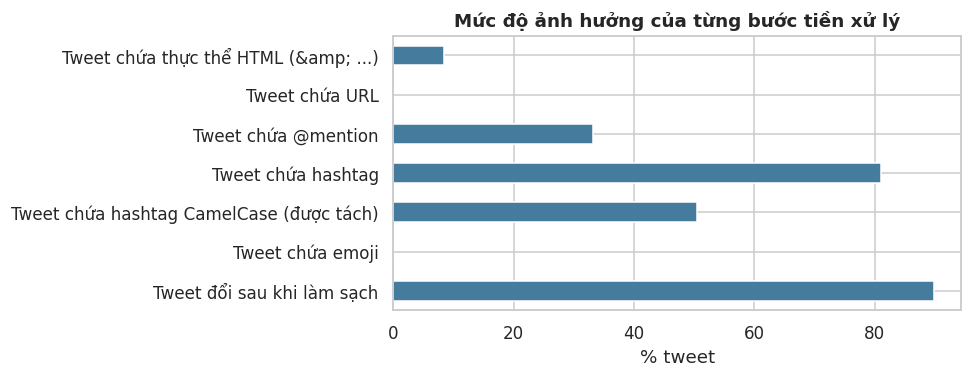

Tweet rỗng sau làm sạch: 0


In [ ]:
# ---- Thống kê tác động của từng bước ----
raw = df.text
steps = pd.Series({
    "Tweet chứa thực thể HTML (&amp; ...)": raw.str.contains(r"&\w+;").sum(),
    "Tweet chứa URL": raw.str.contains(r"https?://|www\.").sum(),
    "Tweet chứa @mention": raw.str.contains(r"@\w+").sum(),
    "Tweet chứa hashtag": raw.str.contains(r"#\w+").sum(),
    "Tweet chứa hashtag CamelCase (được tách)": raw.str.contains(r"#\w*[a-z][A-Z]\w*").sum(),
    "Tweet chứa emoji": raw.apply(lambda s: emoji.emoji_count(s) > 0).sum(),
    "Tweet đổi sau khi làm sạch": (raw != df.text_clean).sum(),
})
stp = steps.to_frame("Số tweet"); stp["Tỉ lệ (%)"] = (stp["Số tweet"] / len(df) * 100).round(1)
display(stp)
fig, ax = plt.subplots(figsize=(9, 3.6))
stp["Tỉ lệ (%)"].iloc[::-1].plot(kind="barh", color="#457b9d", ax=ax); ax.set_xlabel("% tweet"); ax.set_title("Mức độ ảnh hưởng của từng bước tiền xử lý")
plt.tight_layout(); plt.show()
print("Tweet rỗng sau làm sạch:", int((df.text_clean.str.len() == 0).sum()))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

count    21574.0
mean        45.9
std         15.2
min         15.0
50%         45.0
90%         66.0
95%         70.0
99%         77.0
max        105.0
Name: n_tokens, dtype: float64
Tỉ lệ bị cắt khi max_len=128: 0.00%


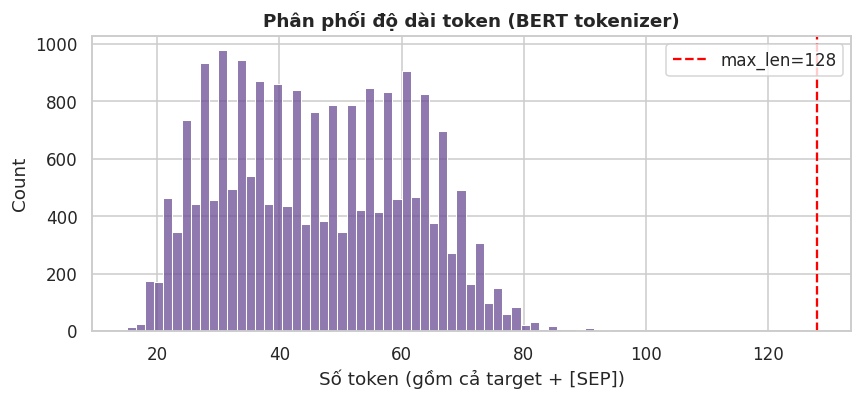

In [ ]:
# ---- Độ dài sau tokenize & lý do chọn max_len = 128 (bài báo) ----
from transformers import AutoTokenizer
_tk = AutoTokenizer.from_pretrained(MODELS["BERT-base"])
enc = _tk(df.target_name.tolist(), df.text_clean.tolist(), truncation=False)
df["n_tokens"] = [len(x) for x in enc["input_ids"]]
print(df.n_tokens.describe(percentiles=[.5, .9, .95, .99]).round(1))
print(f"Tỉ lệ bị cắt khi max_len={MAX_LEN}: {(df.n_tokens > MAX_LEN).mean() * 100:.2f}%")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(df.n_tokens, bins=60, color="#6a4c93", ax=ax); ax.axvline(MAX_LEN, color="red", ls="--", label=f"max_len={MAX_LEN}")
ax.set_xlabel("Số token (gồm cả target + [SEP])"); ax.set_title("Phân phối độ dài token (BERT tokenizer)"); ax.legend(); plt.tight_layout(); plt.show()
df.to_csv(OUT_DIR / "pstance_clean.csv", index=False)

# 5. Cài đặt các mô hình

## 5A. Baseline cổ điển — TF-IDF + Logistic Regression (không biết mục tiêu)
- Chỉ nhìn **nội dung tweet** (không có thông tin target) → cận dưới để thấy giá trị của việc đưa target vào mô hình.
- Huấn luyện một mô hình trên train của cả 3 mục tiêu; chọn `C` và n-gram bằng **Macro-F1 trên tập val**.
- `class_weight="balanced"` để xử lý lệch nhãn (đặc biệt Sanders).

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

def make_baseline(C, ngram):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=2, max_df=0.95, sublinear_tf=True, max_features=100000)),
        ("lr", LogisticRegression(C=C, max_iter=2000, class_weight="balanced", solver="liblinear")),
    ])

grid = []
for ngram in [(1, 1), (1, 2)]:
    for C in [0.1, 0.3, 1, 3, 10]:
        m = make_baseline(C, ngram).fit(tr_all.text_tfidf, tr_all.label)
        sc = per_target_scores(va_all, m.predict(va_all.text_tfidf))
        grid.append({"ngram": ngram, "C": C, **{k: round(v, 2) for k, v in sc.items()}})
grid = pd.DataFrame(grid).sort_values("Fmacro", ascending=False)
display(grid)
best_cfg = grid.iloc[0]
print("Cấu hình tốt nhất trên VAL:", best_cfg["ngram"], "C =", best_cfg["C"])

base_final = make_baseline(best_cfg["C"], best_cfg["ngram"]).fit(tr_all.text_tfidf, tr_all.label)
base_probs = base_final.predict_proba(te_all.text_tfidf)[:, 1]
base_scores = per_target_scores(te_all, (base_probs >= .5).astype(int))
print("Baseline - Macro-F1 test (%):", {k: round(v, 2) for k, v in base_scores.items()})

# Những từ có trọng số lớn nhất của mô hình (để diễn giải)
vec, lr = base_final.named_steps["tfidf"], base_final.named_steps["lr"]
coef = pd.Series(lr.coef_[0], index=vec.get_feature_names_out()).sort_values()
print("Từ đẩy về AGAINST:", list(coef.index[:12]))
print("Từ đẩy về FAVOR  :", list(coef.index[-12:][::-1]))

,ngram,C,trump,biden,bernie,Fmacro
9,"(1, 2)",10.0,72.08,71.84,65.47,69.80
8,"(1, 2)",3.0,72.37,71.64,64.99,69.67
7,"(1, 2)",1.0,72.26,72.02,64.05,69.44
3,"(1, 1)",3.0,72.34,71.28,64.63,69.42
2,"(1, 1)",1.0,70.89,71.77,65.30,69.32
4,"(1, 1)",10.0,71.64,71.33,63.78,68.92
1,"(1, 1)",0.3,70.81,71.42,64.34,68.86
6,"(1, 2)",0.3,71.43,71.50,63.43,68.79
0,"(1, 1)",0.1,69.61,70.42,62.89,67.64
5,"(1, 2)",0.1,69.40,70.18,61.65,67.08


Cấu hình tốt nhất trên VAL: (1, 2) C = 10.0
Baseline - Macro-F1 test (%): {'trump': 72.71, 'biden': 71.33, 'bernie': 64.42, 'Fmacro': 69.49}
Từ đẩy về AGAINST: ['creepy', 'gop', 'sleepy', 'won win', 'his', 'ukraine', 'socialist', 'lying', 'hunter', 'he', 'dementia', 'trump and']
Từ đẩy về FAVOR  : ['love', 'great', 'tcot', 'kag', 'patriots', 'president trump', 'biden joebiden', 'join', 'thank you', 'biden joe', 'dems', 'our']


In [ ]:
# Phụ lục baseline: (i) ad-hoc (mỗi mục tiêu một mô hình), (ii) cross-target (train 2 mục tiêu, test mục tiêu còn lại)
bl_adhoc, bl_cross = {}, {}
for t in TARGETS:
    m = make_baseline(best_cfg["C"], best_cfg["ngram"]).fit(tr_all[tr_all.target == t].text_tfidf, tr_all[tr_all.target == t].label)
    sub = te_all[te_all.target == t]
    bl_adhoc[t] = f1m(sub.label, m.predict(sub.text_tfidf)) * 100

    src = tr_all[tr_all.target != t]
    m = make_baseline(best_cfg["C"], best_cfg["ngram"]).fit(src.text_tfidf, src.label)
    bl_cross[t] = f1m(sub.label, m.predict(sub.text_tfidf)) * 100
bl_adhoc["Fmacro"] = np.mean([bl_adhoc[t] for t in TARGETS])
print("Baseline ad-hoc  :", {k: round(v, 2) for k, v in bl_adhoc.items()})
print("Baseline cross-target:", {k: round(v, 2) for k, v in bl_cross.items()})

Baseline ad-hoc  : {'trump': 76.28, 'biden': 76.35, 'bernie': 69.79, 'Fmacro': np.float64(74.14)}
Baseline cross-target: {'trump': 54.69, 'biden': 57.78, 'bernie': 55.12}


## 5B. Zero-shot — `facebook/bart-large-mnli` (không huấn luyện)
Chuyển bài toán thành **suy luận ngôn ngữ tự nhiên (NLI)**: *premise* = tweet, *hypothesis* = "The author of this tweet is **in favor of / against** *<target>*."
Đây chính là câu hỏi "Is this tweet in favor of [target]?" viết lại dạng khẳng định (NLI cần hypothesis dạng câu khẳng định). Điểm entailment của hai giả thuyết được so sánh (softmax) → FAVOR/AGAINST.
Ta thử 3 mẫu hypothesis trên **một tập con của VAL** (không đụng test) rồi chọn mẫu tốt nhất.

In [ ]:
from transformers import pipeline
zs_kwargs = dict(model="facebook/bart-large-mnli", device=0 if USE_AMP else -1)
if USE_AMP:
    zs_kwargs["torch_dtype"] = torch.float16
zs_pipe = pipeline("zero-shot-classification", **zs_kwargs)

TEMPLATES = {
    "T1": "The author of this tweet is {}.",
    "T2": "This tweet expresses a stance that is {}.",
    "T3": "The speaker's opinion is {}.",
}
ZS_BS = 16

def zs_prob_favor(texts, target_name, template):
    labels = [f"in favor of {target_name}", f"against {target_name}"]
    outs = zs_pipe(list(texts), candidate_labels=labels, hypothesis_template=template, batch_size=ZS_BS)
    if isinstance(outs, dict):
        outs = [outs]
    return np.array([dict(zip(o["labels"], o["scores"]))[labels[0]] for o in outs])

# ---- chọn template trên tập con VAL (150 tweet / mục tiêu) ----
n_sub = 30 if QUICK_MODE else 150
val_sub = va_all.groupby("target", group_keys=False).sample(n=min(n_sub, int(va_all.groupby("target").size().min())), random_state=0)
tpl_rows = []
for k, tpl in TEMPLATES.items():
    pred = np.zeros(len(val_sub), dtype=int)
    for t in TARGETS:
        m = (val_sub.target == t).values
        pred[m] = (zs_prob_favor(val_sub.text_clean[m], TARGET_NAME[t], tpl) >= .5).astype(int)
    tpl_rows.append({"template": k, "hypothesis": tpl, **{c: round(v, 2) for c, v in per_target_scores(val_sub, pred).items()}})
tpl_df = pd.DataFrame(tpl_rows); display(tpl_df)
BEST_TPL = tpl_df.sort_values("Fmacro", ascending=False).iloc[0]["template"]
print("Template được chọn:", BEST_TPL, "->", TEMPLATES[BEST_TPL])

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

,template,hypothesis,trump,biden,bernie,Fmacro
0,T1,The author of this tweet is {}.,61.17,66.27,73.99,67.14
1,T2,This tweet expresses a stance that is {}.,53.86,67.27,71.98,64.37
2,T3,The speaker's opinion is {}.,59.81,70.76,76.67,69.08


Template được chọn: T3 -> The speaker's opinion is {}.


In [ ]:
ZS_FILE = RES_DIR / ("zs_test_quick.npy" if QUICK_MODE else "zs_test.npy")
if ZS_FILE.exists():
    zs_probs = np.load(ZS_FILE)
else:
    zs_probs = np.zeros(len(te_all))
    t0 = time.time()
    for t in TARGETS:
        m = (te_all.target == t).values
        zs_probs[m] = zs_prob_favor(te_all.text_clean[m], TARGET_NAME[t], TEMPLATES[BEST_TPL])
        print(f"  zero-shot xong {TARGET_NAME[t]}: {m.sum()} tweet ({time.time() - t0:.0f}s)")
    np.save(ZS_FILE, zs_probs)
zs_scores = per_target_scores(te_all, (zs_probs >= .5).astype(int))
print("Zero-shot - Macro-F1 test (%):", {k: round(v, 2) for k, v in zs_scores.items()})
print("Tỉ lệ dự đoán FAVOR:", round((zs_probs >= .5).mean() * 100, 1), "% | thực tế FAVOR:", round(te_all.label.mean() * 100, 1), "%")
del zs_pipe; free_gpu()

Zero-shot - Macro-F1 test (%): {'trump': 67.03, 'biden': 72.84, 'bernie': 70.05, 'Fmacro': 69.97}
Tỉ lệ dự đoán FAVOR: 42.2 % | thực tế FAVOR: 47.8 %


## 5C. Fine-tune 3 kiến trúc pretrained × 3 seed
**Thiết lập (theo bài báo):** `max_len=128`, `batch=32`, AdamW `lr=2e-5`, 3 epoch; thêm warm-up tuyến tính 10% + weight decay 0.01, mixed precision (fp16), gradient clipping 1.0.
**Chọn epoch tốt nhất theo Macro-F1 trên VAL** (không nhìn test).
**Chiến lược huấn luyện "Merged"** của bài báo: *một* mô hình huấn luyện trên cả 3 mục tiêu (target nằm trong input), đánh giá riêng từng mục tiêu.
Kết quả mỗi lần chạy được cache vào Drive → chạy lại ô sẽ tự bỏ qua các lần đã xong.

In [ ]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader

_tok_cache = {}
def get_tok(name):
    if name not in _tok_cache:
        _tok_cache[name] = AutoTokenizer.from_pretrained(name)
    return _tok_cache[name]

def encode(d, tok):
    enc = tok(d.target_name.tolist(), d.text_clean.tolist(), truncation="only_second", max_length=MAX_LEN)
    items = [{k: enc[k][i] for k in enc.keys()} for i in range(len(d))]
    for it, l in zip(items, d.label.tolist()):
        it["labels"] = int(l)
    return items

@torch.no_grad()
def predict_probs(model, loader):
    model.eval(); out = []
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**b).logits
        out.append(torch.softmax(logits.float(), -1)[:, 1].cpu().numpy())   # xác suất FAVOR
    return np.concatenate(out)

def train_one(hf_name, seed, tr, va, te, save_dir=None, save_thr=-1.0):
    set_seed(seed)
    tok = get_tok(hf_name); coll = DataCollatorWithPadding(tok)
    g = torch.Generator(); g.manual_seed(seed)
    dl_tr = DataLoader(encode(tr, tok), batch_size=BATCH, shuffle=True, collate_fn=coll, generator=g)
    dl_va = DataLoader(encode(va, tok), batch_size=64, shuffle=False, collate_fn=coll)
    dl_te = DataLoader(encode(te, tok), batch_size=64, shuffle=False, collate_fn=coll)

    model = AutoModelForSequenceClassification.from_pretrained(hf_name, num_labels=2).to(DEVICE)
    no_decay = ["bias", "LayerNorm.weight"]
    groups = [
        {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": WD},
        {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
    ]
    opt = torch.optim.AdamW(groups, lr=LR)
    total = len(dl_tr) * EPOCHS
    sch = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    best = {"val_f1": -1.0}; hist = []; best_state = None
    for ep in range(1, EPOCHS + 1):
        model.train(); tl = 0.0
        for b in dl_tr:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**b).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            tl += loss.item()
        pv = predict_probs(model, dl_va)
        vf = f1m(va.label.values, (pv >= .5).astype(int)) * 100
        hist.append({"epoch": ep, "train_loss": tl / len(dl_tr), "val_macro_f1": vf})
        if vf > best["val_f1"]:
            best.update(val_f1=vf, epoch=ep, val_probs=pv, test_probs=predict_probs(model, dl_te))
            if save_dir is not None:
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    best["hist"] = hist
    if save_dir is not None and best["val_f1"] > save_thr and best_state is not None:
        model.load_state_dict(best_state); Path(save_dir).mkdir(parents=True, exist_ok=True)
        model.save_pretrained(save_dir); tok.save_pretrained(save_dir); best["saved"] = True
    del model, opt, best_state; free_gpu()
    return best

def cached(path, fn):
    path = Path(path)
    if path.exists():
        return pickle.load(open(path, "rb"))
    r = fn(); pickle.dump(r, open(path, "wb")); return r

BEST_FILE = WORK / ("best_models_quick.json" if QUICK_MODE else "best_models.json")
BEST_INFO = json.load(open(BEST_FILE)) if BEST_FILE.exists() else {}
TAG = "q" if QUICK_MODE else "f"
print("Đã sẵn sàng. Chế độ:", "QUICK" if QUICK_MODE else "ĐẦY ĐỦ")

Đã sẵn sàng. Chế độ: ĐẦY ĐỦ


### 5C-1. Fine-tune in-target (merged) — 3 kiến trúc × 3 seed
Mỗi kiến trúc lưu lại **mô hình tốt nhất theo VAL** (một seed) vào Drive để dùng cho demo.

In [ ]:
in_results = {}      # in_results[arch][seed] = dict(val_f1, epoch, test_probs, hist)
for arch, hf in MODELS.items():
    in_results[arch] = {}
    for seed in SEEDS:
        t0 = time.time()
        def run():
            thr = BEST_INFO.get(arch, {}).get("val_f1", -1.0)
            r = train_one(hf, seed, tr_all, va_all, te_all, save_dir=MODEL_DIR / (TAG + "_" + arch), save_thr=thr)
            return r
        r = cached(RES_DIR / f"in_{TAG}_{arch}_{seed}.pkl", run)
        if r.get("saved"):
            BEST_INFO[arch] = {"val_f1": r["val_f1"], "seed": seed}
            json.dump(BEST_INFO, open(BEST_FILE, "w"))
        in_results[arch][seed] = r
        sc = per_target_scores(te_all, (r["test_probs"] >= .5).astype(int))
        print(f"{arch:13s} seed={seed:<5d} best_epoch={r['epoch']} val_F1={r['val_f1']:.2f} | test Fmacro={sc['Fmacro']:.2f} ({time.time() - t0:.0f}s)")

BERT-base     seed=42    best_epoch=3 val_F1=77.11 | test Fmacro=78.46 (0s)
BERT-base     seed=123   best_epoch=2 val_F1=77.06 | test Fmacro=77.37 (0s)
BERT-base     seed=2024  best_epoch=3 val_F1=77.18 | test Fmacro=78.02 (0s)
RoBERTa-base  seed=42    best_epoch=3 val_F1=80.82 | test Fmacro=80.74 (0s)
RoBERTa-base  seed=123   best_epoch=2 val_F1=81.80 | test Fmacro=80.27 (0s)
RoBERTa-base  seed=2024  best_epoch=3 val_F1=80.91 | test Fmacro=80.31 (1s)
DistilBERT    seed=42    best_epoch=3 val_F1=76.74 | test Fmacro=77.45 (1s)
DistilBERT    seed=123   best_epoch=3 val_F1=76.94 | test Fmacro=77.45 (0s)
DistilBERT    seed=2024  best_epoch=2 val_F1=76.50 | test Fmacro=76.52 (0s)


### 5C-2. Cross-target THẬT SỰ (Yêu cầu nâng cao – bắt buộc để đạt điểm 8-10)
Huấn luyện + chọn epoch (VAL) trên **2 mục tiêu nguồn**, kiểm thử trên **tập test của mục tiêu còn lại** (mô hình chưa từng thấy mục tiêu đó khi huấn luyện).
Ba cấu hình: (Biden+Sanders → Trump), (Trump+Sanders → Biden), (Trump+Biden → Sanders). Báo cáo **mức giảm** so với in-target.

In [ ]:
cross_results = {}   # cross_results[arch][heldout][seed] = dict(test_probs, ...)   (test_probs căn theo te_all[te_all.target == heldout])
for arch in CROSS_MODELS:
    cross_results[arch] = {}
    for held in TARGETS:
        cross_results[arch][held] = {}
        src = [t for t in TARGETS if t != held]
        tr_s, va_s = tr_all[tr_all.target.isin(src)], va_all[va_all.target.isin(src)]
        te_h = te_all[te_all.target == held]
        for seed in SEEDS:
            t0 = time.time()
            r = cached(RES_DIR / f"cross_{TAG}_{arch}_{held}_{seed}.pkl",
                       lambda: train_one(MODELS[arch], seed, tr_s, va_s, te_h))
            cross_results[arch][held][seed] = r
            f = f1m(te_h.label.values, (r["test_probs"] >= .5).astype(int)) * 100
            print(f"{arch:13s} {'+'.join(TARGET_NAME[s].split()[-1] for s in src):>14s} -> {TARGET_NAME[held]:15s} seed={seed:<5d} Macro-F1={f:.2f} ({time.time() - t0:.0f}s)")

BERT-base      Biden+Sanders -> Donald Trump    seed=42    Macro-F1=58.42 (0s)
BERT-base      Biden+Sanders -> Donald Trump    seed=123   Macro-F1=63.29 (0s)
BERT-base      Biden+Sanders -> Donald Trump    seed=2024  Macro-F1=62.33 (0s)
BERT-base      Trump+Sanders -> Joe Biden       seed=42    Macro-F1=67.06 (0s)
BERT-base      Trump+Sanders -> Joe Biden       seed=123   Macro-F1=71.31 (0s)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT-base        Trump+Biden -> Bernie Sanders  seed=123   Macro-F1=59.52 (183s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT-base        Trump+Biden -> Bernie Sanders  seed=2024  Macro-F1=60.03 (183s)


# 6. Đánh giá và so sánh mô hình

### 6.1 Bảng tổng hợp Macro-F1 (%) theo mục tiêu — mean ± std qua các seed
Baseline và zero-shot là mô hình tất định (không có seed) nên không có std.

In [ ]:
rows = []
rows.append({"model": "Baseline TF-IDF+LR", "seed": "-", **base_scores})
rows.append({"model": "Zero-shot BART-MNLI", "seed": "-", **zs_scores})
for arch in MODELS:
    for seed in SEEDS:
        r = in_results[arch][seed]
        rows.append({"model": arch, "seed": seed, **per_target_scores(te_all, (r["test_probs"] >= .5).astype(int)),
                     "val_F1": r["val_f1"], "best_epoch": r["epoch"]})
runs = pd.DataFrame(rows)
print("Kết quả TỪNG lần chạy (Macro-F1 %, tập test):")
display(runs.round(2))

order = ["Baseline TF-IDF+LR", "Zero-shot BART-MNLI"] + list(MODELS)
mean_t = runs.groupby("model")[TARGETS + ["Fmacro"]].mean().reindex(order)
std_t = runs.groupby("model")[TARGETS + ["Fmacro"]].std(ddof=1).reindex(order).fillna(0)

summary = pd.DataFrame(index=order)
for c in TARGETS + ["Fmacro"]:
    summary[TARGET_NAME.get(c, "Fmacro (TB 3 mục tiêu)")] = [f"{mean_t.loc[m, c]:.2f} ± {std_t.loc[m, c]:.2f}" for m in order]
print("\nBẢNG TỔNG HỢP: mean ± std (std mẫu, ddof=1) trên", len(SEEDS), "seed")
display(summary)

ref = pd.DataFrame(PAPER_INTARGET).T.rename(columns={"trump": "Donald Trump", "biden": "Joe Biden", "bernie": "Bernie Sanders", "Fmacro": "Fmacro (TB 3 mục tiêu)"})
print("Số liệu tham chiếu từ bài báo (Bảng 9):")
display(ref.round(2))
summary.to_csv(OUT_DIR / "summary_in_target.csv"); runs.to_csv(OUT_DIR / "runs_in_target.csv", index=False)

Kết quả TỪNG lần chạy (Macro-F1 %, tập test):


,model,seed,trump,biden,bernie,Fmacro,val_F1,best_epoch
0,Baseline TF-IDF+LR,-,72.71,71.33,64.42,69.49,NaN,NaN
1,Zero-shot BART-MNLI,-,67.03,72.84,70.05,69.97,NaN,NaN
2,BERT-base,42,81.57,79.30,74.52,78.46,77.11,3.0
3,BERT-base,123,79.94,78.81,73.37,77.37,77.06,2.0
4,BERT-base,2024,80.19,79.10,74.77,78.02,77.18,3.0
5,RoBERTa-base,42,83.01,81.10,78.09,80.74,80.82,3.0
6,RoBERTa-base,123,82.43,82.18,76.19,80.27,81.80,2.0
7,RoBERTa-base,2024,83.03,81.20,76.72,80.31,80.91,3.0
8,DistilBERT,42,78.98,80.35,73.03,77.45,76.74,3.0
9,DistilBERT,123,79.48,79.43,73.43,77.45,76.94,3.0



BẢNG TỔNG HỢP: mean ± std (std mẫu, ddof=1) trên 3 seed


,Donald Trump,Joe Biden,Bernie Sanders,Fmacro (TB 3 mục tiêu)
Baseline TF-IDF+LR,72.71 ± 0.00,71.33 ± 0.00,64.42 ± 0.00,69.49 ± 0.00
Zero-shot BART-MNLI,67.03 ± 0.00,72.84 ± 0.00,70.05 ± 0.00,69.97 ± 0.00
BERT-base,80.57 ± 0.88,79.07 ± 0.25,74.22 ± 0.74,77.95 ± 0.55
RoBERTa-base,82.83 ± 0.34,81.49 ± 0.60,77.00 ± 0.98,80.44 ± 0.26
DistilBERT,78.64 ± 1.05,80.15 ± 0.65,72.62 ± 1.07,77.14 ± 0.54


Số liệu tham chiếu từ bài báo (Bảng 9):


,Donald Trump,Joe Biden,Bernie Sanders,Fmacro (TB 3 mục tiêu)
[Bài báo] BERT ad-hoc,78.28,78.70,72.45,76.48
[Bài báo] BERT merged,79.19,76.02,73.59,76.27
[Bài báo] BERTweet merged,83.81,79.08,77.75,80.21


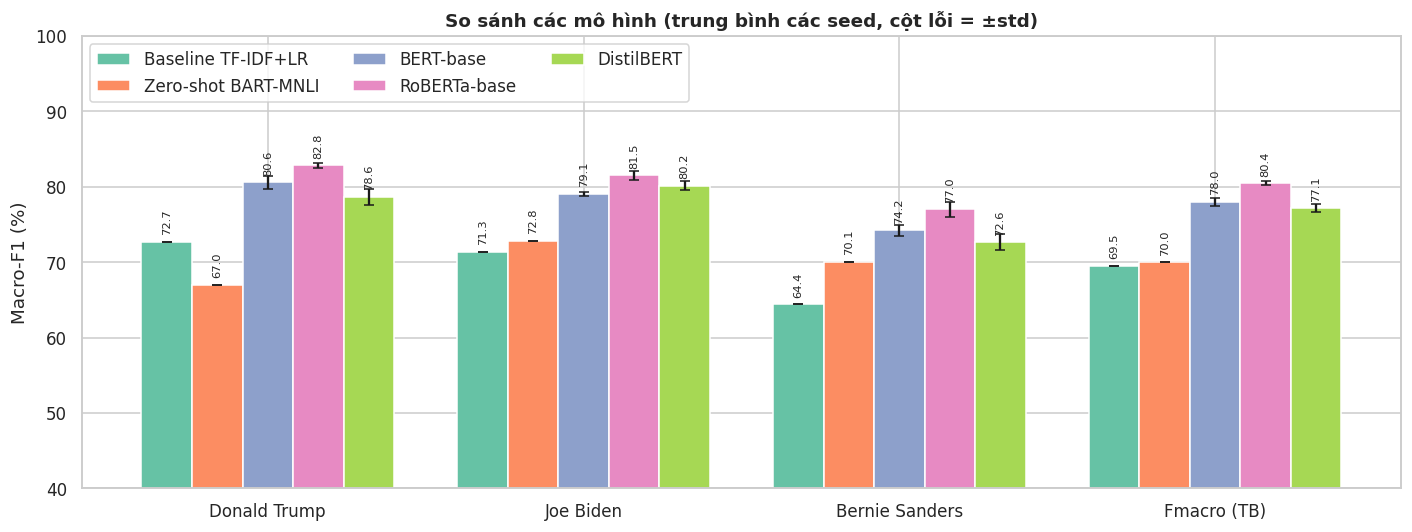

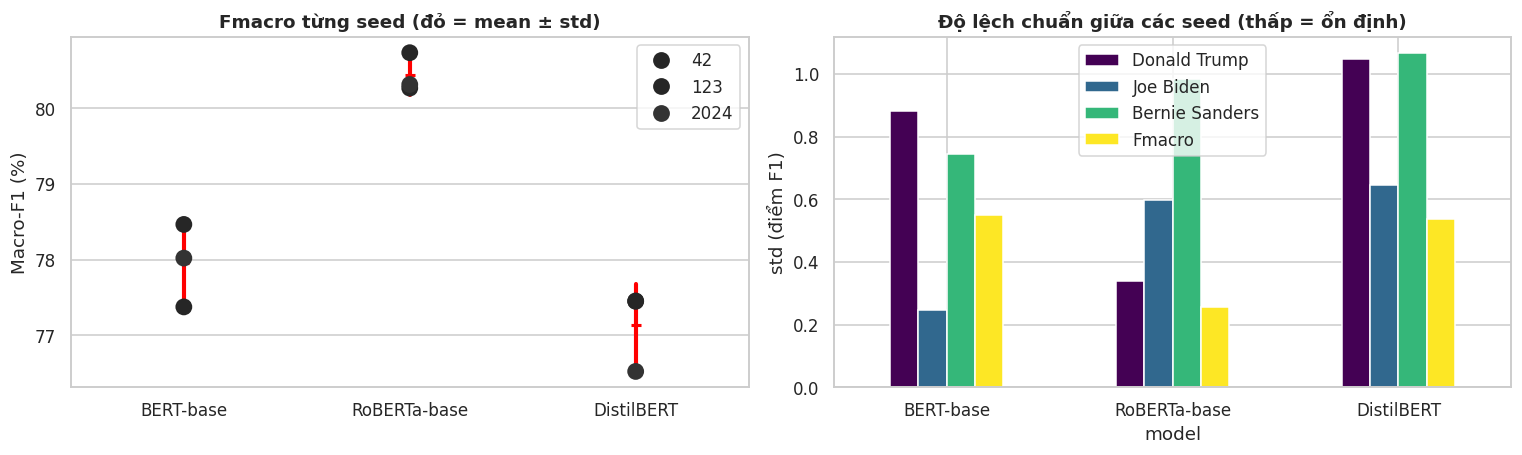

In [ ]:
# ---- Biểu đồ so sánh: Macro-F1 theo mục tiêu (cột lỗi = std giữa các seed) ----
fig, ax = plt.subplots(figsize=(13, 5))
cols = TARGETS + ["Fmacro"]; labels = [TARGET_NAME[t] for t in TARGETS] + ["Fmacro (TB)"]
w = 0.16; x = np.arange(len(cols)); palette = sns.color_palette("Set2", len(order))
for i, m in enumerate(order):
    ax.bar(x + (i - (len(order) - 1) / 2) * w, mean_t.loc[m, cols], w, yerr=std_t.loc[m, cols], capsize=3, label=m, color=palette[i])
    for xi, v in zip(x + (i - (len(order) - 1) / 2) * w, mean_t.loc[m, cols]):
        ax.text(xi, v + 1.2, f"{v:.1f}", ha="center", fontsize=7.5, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(40, 100); ax.set_ylabel("Macro-F1 (%)")
ax.set_title("So sánh các mô hình (trung bình các seed, cột lỗi = ±std)"); ax.legend(ncol=3, loc="upper left"); plt.tight_layout(); plt.show()

# ---- Độ ổn định giữa các seed ----
ft = runs[runs.model.isin(MODELS)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
sns.stripplot(data=ft, x="model", y="Fmacro", hue="seed", size=11, ax=axes[0], palette="dark:#333", jitter=False)
sns.pointplot(data=ft, x="model", y="Fmacro", errorbar="sd", color="red", markers="_", linestyles="", ax=axes[0])
axes[0].set_title("Fmacro từng seed (đỏ = mean ± std)"); axes[0].set_xlabel(""); axes[0].set_ylabel("Macro-F1 (%)")
std_plot = std_t.loc[list(MODELS), TARGETS + ["Fmacro"]].rename(columns=TARGET_NAME)
std_plot.plot(kind="bar", ax=axes[1], rot=0, colormap="viridis"); axes[1].set_title("Độ lệch chuẩn giữa các seed (thấp = ổn định)"); axes[1].set_ylabel("std (điểm F1)")
plt.tight_layout(); plt.show()

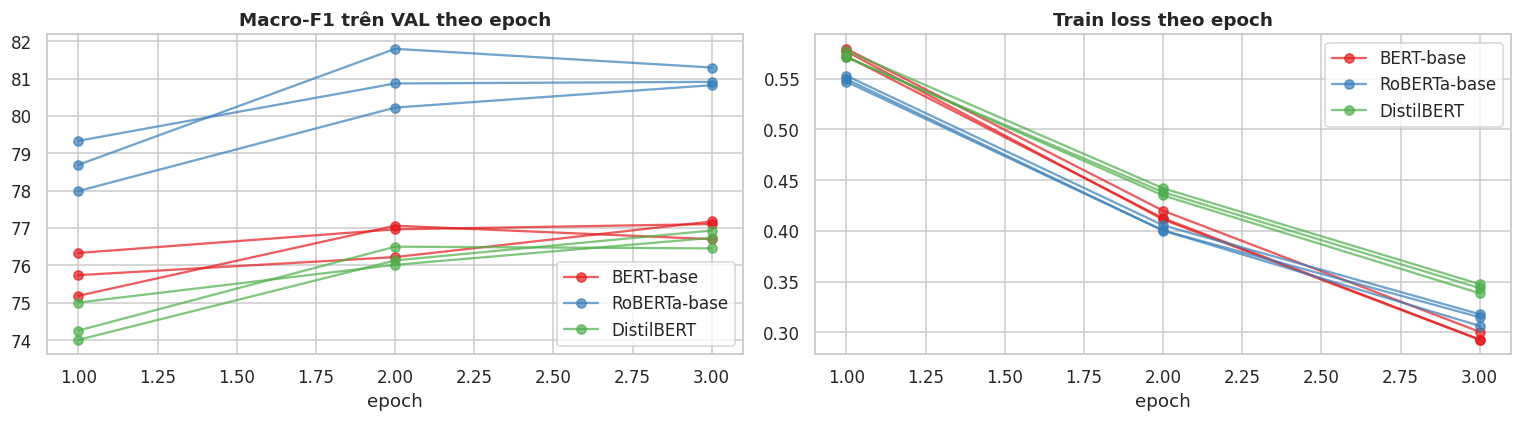

In [ ]:
# ---- Đường cong huấn luyện (val Macro-F1 & train loss theo epoch) ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for arch, col in zip(MODELS, sns.color_palette("Set1", 3)):
    for seed in SEEDS:
        h = pd.DataFrame(in_results[arch][seed]["hist"])
        axes[0].plot(h.epoch, h.val_macro_f1, "-o", color=col, alpha=.7, label=arch if seed == SEEDS[0] else None)
        axes[1].plot(h.epoch, h.train_loss, "-o", color=col, alpha=.7, label=arch if seed == SEEDS[0] else None)
axes[0].set_title("Macro-F1 trên VAL theo epoch"); axes[1].set_title("Train loss theo epoch")
for a in axes: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

### 6.2 Confusion matrix, precision / recall theo lớp
Với mô hình fine-tune dùng **seed đầu tiên** (`SEEDS[0]`) để vẽ và phân tích lỗi.

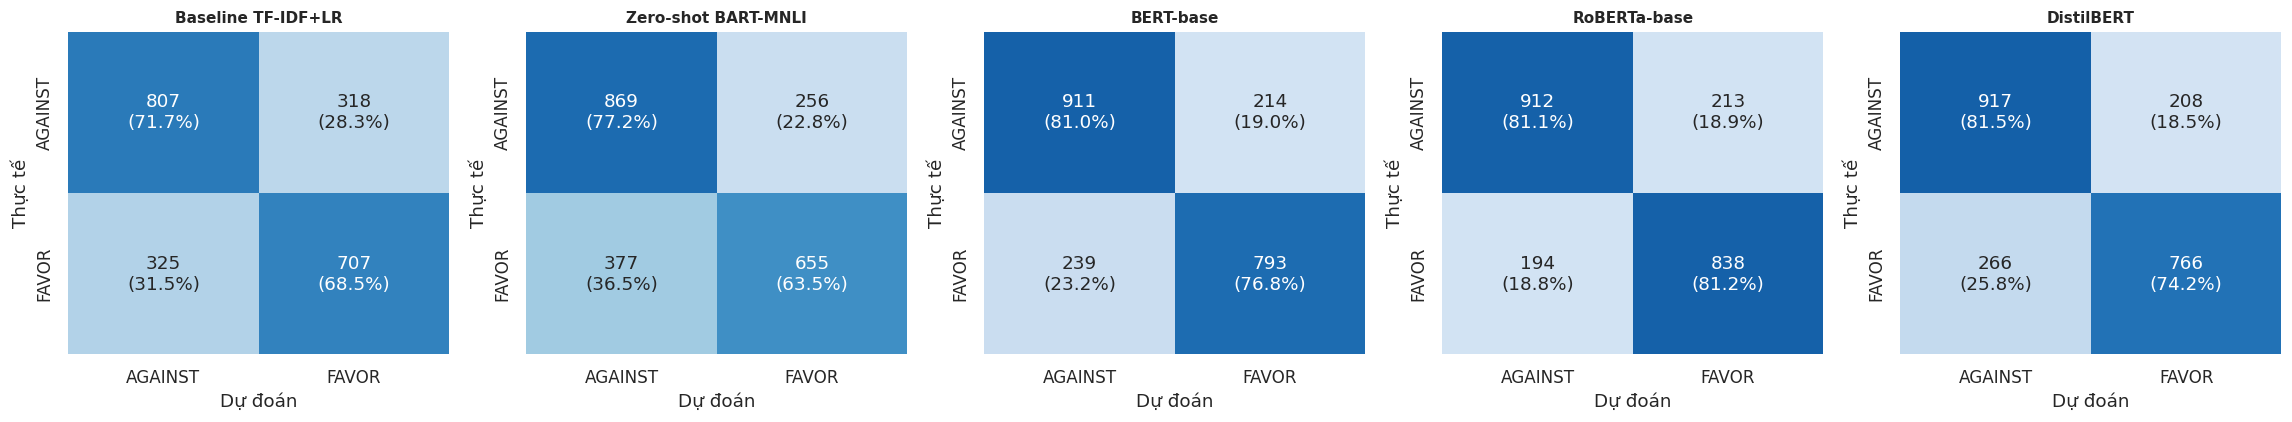

,Acc,P_FAVOR,R_FAVOR,F1_FAVOR,P_AGAINST,R_AGAINST,F1_AGAINST,Macro-F1
model,,,,,,,,
Baseline TF-IDF+LR,70.19,68.98,68.51,68.74,71.29,71.73,71.51,70.13
Zero-shot BART-MNLI,70.65,71.90,63.47,67.42,69.74,77.24,73.30,70.36
BERT-base,79.00,78.75,76.84,77.78,79.22,80.98,80.09,78.94
RoBERTa-base,81.13,79.73,81.20,80.46,82.46,81.07,81.76,81.11
DistilBERT,78.03,78.64,74.22,76.37,77.51,81.51,79.46,77.92


In [ ]:
P = {  # xác suất FAVOR trên te_all (dùng cho đánh giá & phân tích lỗi)
    "Baseline TF-IDF+LR": base_probs,
    "Zero-shot BART-MNLI": zs_probs,
}
for arch in MODELS:
    P[arch] = in_results[arch][SEEDS[0]]["test_probs"]
MODEL_ORDER = list(P)
yt = te_all.label.values
PRED = {m: (p >= .5).astype(int) for m, p in P.items()}

fig, axes = plt.subplots(1, len(P), figsize=(4.2 * len(P), 4))
for ax, m in zip(axes, MODEL_ORDER):
    cm = confusion_matrix(yt, PRED[m]); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cm[i, j]}\n({cmn[i, j] * 100:.1f}%)" for j in range(2)] for i in range(2)]), fmt="", cmap="Blues",
                xticklabels=["AGAINST", "FAVOR"], yticklabels=["AGAINST", "FAVOR"], cbar=False, ax=ax, vmin=0, vmax=1)
    ax.set_title(m, fontsize=10); ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
plt.tight_layout(); plt.show()

rows = []
for m in MODEL_ORDER:
    p, r, f, _ = precision_recall_fscore_support(yt, PRED[m], labels=[1, 0], zero_division=0)
    rows.append({"model": m, "Acc": accuracy_score(yt, PRED[m]) * 100, "P_FAVOR": p[0] * 100, "R_FAVOR": r[0] * 100, "F1_FAVOR": f[0] * 100,
                 "P_AGAINST": p[1] * 100, "R_AGAINST": r[1] * 100, "F1_AGAINST": f[1] * 100, "Macro-F1": (f[0] + f[1]) / 2 * 100})
cls_tab = pd.DataFrame(rows).set_index("model").round(2); display(cls_tab)

### 6.3 Cross-target: mức giảm hiệu năng khi gặp mục tiêu chưa từng thấy
`Giảm = F1 in-target (mô hình merged trên mục tiêu đó) − F1 cross-target (held-out)`.

,model,held-out,in-target,cross mean,cross std,Giảm (điểm F1),Giảm (%)
0,Baseline TF-IDF+LR,Donald Trump,72.71,54.69,0.00,18.02,24.78
1,Baseline TF-IDF+LR,Joe Biden,71.33,57.78,0.00,13.55,18.99
2,Baseline TF-IDF+LR,Bernie Sanders,64.42,55.12,0.00,9.31,14.45
3,BERT-base,Donald Trump,80.57,61.35,2.58,19.22,23.85
4,BERT-base,Joe Biden,79.07,69.93,2.49,9.14,11.56
5,BERT-base,Bernie Sanders,74.22,60.26,0.87,13.96,18.81


Tham chiếu bài báo (Bảng 10, huấn luyện trên 2 mục tiêu → test mục tiêu còn lại; cột = mục tiêu held-out):


,Donald Trump,Joe Biden,Bernie Sanders
[Bài báo] BiCE,53.91,53.73,52.26
[Bài báo] CrossNet,56.44,55.57,56.26
[Bài báo] BERTweet,66.01,68.64,69.99


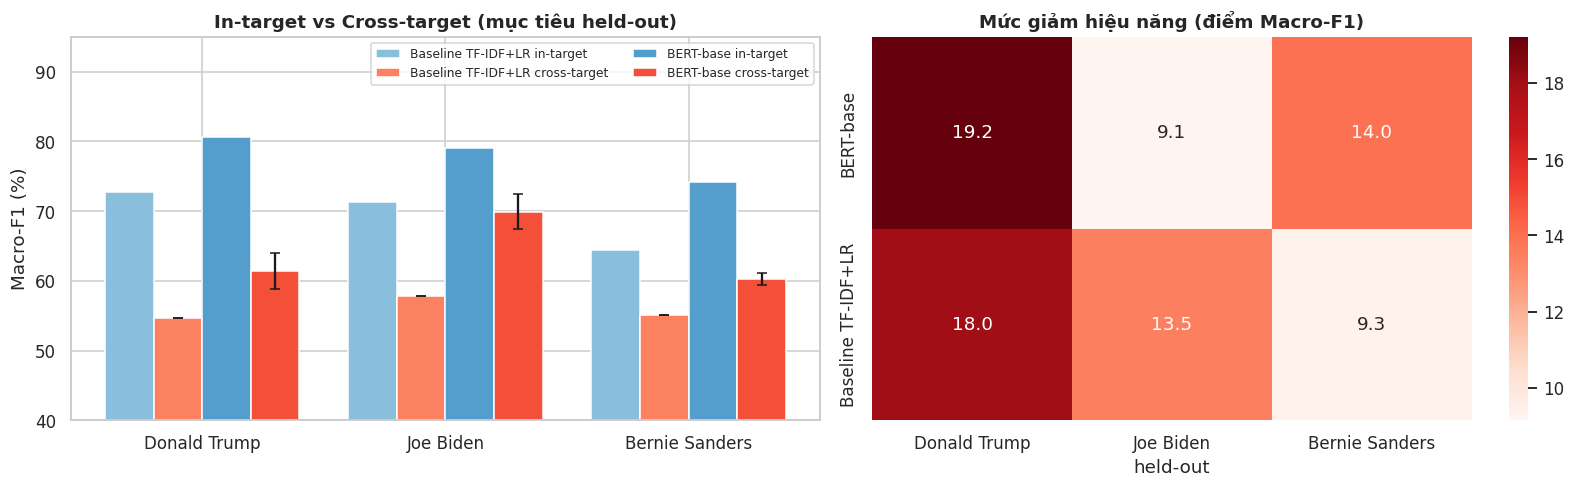

In [ ]:
rows = []
# baseline
for t in TARGETS:
    rows.append({"model": "Baseline TF-IDF+LR", "held-out": TARGET_NAME[t], "in-target": per_target_scores(te_all, PRED["Baseline TF-IDF+LR"])[t],
                 "cross mean": bl_cross[t], "cross std": 0.0})
for arch in CROSS_MODELS:
    for t in TARGETS:
        te_h = te_all[te_all.target == t]
        cr = [f1m(te_h.label.values, (cross_results[arch][t][s]["test_probs"] >= .5).astype(int)) * 100 for s in SEEDS]
        inn = [per_target_scores(te_all, (in_results[arch][s]["test_probs"] >= .5).astype(int))[t] for s in SEEDS]
        rows.append({"model": arch, "held-out": TARGET_NAME[t], "in-target": np.mean(inn), "cross mean": np.mean(cr), "cross std": np.std(cr, ddof=1)})
cross_tab = pd.DataFrame(rows)
cross_tab["Giảm (điểm F1)"] = cross_tab["in-target"] - cross_tab["cross mean"]
cross_tab["Giảm (%)"] = cross_tab["Giảm (điểm F1)"] / cross_tab["in-target"] * 100
display(cross_tab.round(2))
cross_tab.to_csv(OUT_DIR / "cross_target.csv", index=False)

ref_c = pd.DataFrame(PAPER_CROSS).T.rename(columns=TARGET_NAME)[[TARGET_NAME[t] for t in TARGETS]]
print("Tham chiếu bài báo (Bảng 10, huấn luyện trên 2 mục tiêu → test mục tiêu còn lại; cột = mục tiêu held-out):")
display(ref_c.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
pv = cross_tab.pivot(index="model", columns="held-out")
models_c = list(cross_tab.model.unique()); xx = np.arange(len(TARGETS)); wd = 0.8 / (2 * len(models_c))
for i, m in enumerate(models_c):
    sub = cross_tab[cross_tab.model == m].set_index("held-out").loc[[TARGET_NAME[t] for t in TARGETS]]
    axes[0].bar(xx + (2 * i) * wd - 0.4 + wd / 2, sub["in-target"], wd, label=f"{m} in-target", color=sns.color_palette("Blues", 6)[2 + i])
    axes[0].bar(xx + (2 * i + 1) * wd - 0.4 + wd / 2, sub["cross mean"], wd, yerr=sub["cross std"], capsize=3, label=f"{m} cross-target", color=sns.color_palette("Reds", 6)[2 + i])
axes[0].set_xticks(xx); axes[0].set_xticklabels([TARGET_NAME[t] for t in TARGETS]); axes[0].set_ylim(40, 95); axes[0].set_ylabel("Macro-F1 (%)")
axes[0].set_title("In-target vs Cross-target (mục tiêu held-out)"); axes[0].legend(fontsize=8, ncol=2)
hm = cross_tab.pivot(index="model", columns="held-out", values="Giảm (điểm F1)")[[TARGET_NAME[t] for t in TARGETS]]
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", ax=axes[1]); axes[1].set_title("Mức giảm hiệu năng (điểm Macro-F1)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### 6.4 Nhận xét kết quả *(điền sau khi chạy – gợi ý các ý cần nêu để trả lời phản biện)*
1. **Xếp hạng:** mô hình nào tốt nhất / kém nhất trong 3 kiến trúc? Vì sao (RoBERTa huấn luyện lâu hơn trên nhiều dữ liệu hơn; DistilBERT nhỏ hơn ~40% tham số nên thường kém hơn một chút)?
2. **Std giữa các seed:** std nhỏ (< ~1 điểm) → mô hình ổn định, kết quả không do may mắn; std lớn → nhạy với khởi tạo/thứ tự dữ liệu, cần nhiều seed hơn (bài báo dùng 7).
3. **So với baseline/zero-shot:** khoảng cách thể hiện giá trị của fine-tune và của việc đưa *target* vào input.
4. **Cross-target:** mức giảm lớn nhất ở cặp mục tiêu nào? Có phù hợp với phát hiện của EDA (Biden–Sanders cùng đảng, từ vựng giống nhau) và với bài báo (JB↔BS dễ hơn)?
5. **So với bài báo:** số của ta thấp/cao hơn BERT trong bài báo bao nhiêu? (bài báo dùng 7 lần chạy; BERTweet cao hơn BERT vì được pretrain trên tweet).

# 7. Phân tích lỗi

Phân tích trên **tập test**, mô hình fine-tune dùng seed `SEEDS[0]`. Ta gán mỗi tweet vào các **nhóm đặc điểm ngôn ngữ** (heuristic bằng regex/từ khóa) để xem mô hình sai nhiều ở loại tweet nào:

| Nhóm | Cách xác định | Giả thuyết lỗi |
|---|---|---|
| Không nhắc tên mục tiêu (ngầm) | tweet không chứa từ khóa tên nhân vật | cần kiến thức nền/ngữ cảnh sự kiện |
| Nhắc nhân vật/đảng khác | có tên nhân vật khác / đảng / chính trị gia khác | nhầm lập trường đối với người khác thành với mục tiêu |
| Phủ định | not, never, n't, no... | đảo cực ý nghĩa |
| Mỉa mai / câu hỏi tu từ | `?`, lol, "yeah right", trích dẫn... | nghĩa đen ≠ nghĩa thật |
| Tin tức / trích dẫn | URL, said/says/report... | tweet trung tính về cảm xúc nhưng có lập trường ngầm |
| Tweet dài (>40 từ) | số từ > 40 | thông tin dài, nhiều ý, bị cắt/loãng |

In [ ]:
NEG_RE   = re.compile(r"\b(not|no|never|nobody|nothing|neither|nor|without)\b|n't|\bdont\b|\bcant\b|\bwont\b", re.I)
SARC_RE  = re.compile(r"\?|\blol\b|\blmao\b|/s\b|yeah right|\bsure\b|\boh\b|\bwow\b|genius|so-called|\"[^\"]{3,}\"|“[^”]{3,}”", re.I)
NEWS_RE  = re.compile(r"\b(says?|said|announced?|reports?|reported|according|breaking|news|poll|tweeted)\b|https?://", re.I)
OTHER_RE = re.compile(r"(democrat|republican|\bgop\b|\bdnc\b|pelosi|obama|clinton|hillary|pence|warren|buttigieg|harris|mcconnell|schumer|bloomberg|cuomo|fauci|putin|ukrain)", re.I)

CATS = ["Không nhắc tên mục tiêu (ngầm)", "Nhắc nhân vật/đảng khác", "Phủ định", "Mỉa mai / câu hỏi tu từ", "Tin tức / trích dẫn", "Tweet dài (>40 từ)"]

def tag_row(text, target):
    low = text.lower()
    own = any(k in low for k in KEYWORDS[target])
    others = any(any(k in low for k in KEYWORDS[o]) for o in TARGETS if o != target) or bool(OTHER_RE.search(text))
    return {CATS[0]: not own, CATS[1]: others, CATS[2]: bool(NEG_RE.search(text)), CATS[3]: bool(SARC_RE.search(text)),
            CATS[4]: bool(NEWS_RE.search(text)), CATS[5]: len(text.split()) > 40}

tags = pd.DataFrame([tag_row(t, g) for t, g in zip(te_all.text, te_all.target)])
print("Tỉ lệ tweet test thuộc mỗi nhóm (%):")
display((tags.mean() * 100).round(1).to_frame("% tweet").T)

def short(s, n=240):
    return s if len(s) <= n else s[:n] + "…"

def error_report(name):
    p, pred = P[name], PRED[name]; err = pred != yt
    print("=" * 110); print(f"PHÂN TÍCH LỖI: {name}   |   lỗi {err.sum()}/{len(err)} = {err.mean() * 100:.1f}%   |   Macro-F1 = {f1m(yt, pred) * 100:.2f}"); print("=" * 110)

    fig, axes = plt.subplots(1, 4, figsize=(21, 4))
    # (a) tỉ lệ lỗi theo mục tiêu
    er_t = pd.Series({TARGET_NAME[t]: err[(te_all.target == t).values].mean() * 100 for t in TARGETS})
    axes[0].bar(er_t.index, er_t.values, color="#e76f51"); axes[0].set_title("Tỉ lệ lỗi (%) theo mục tiêu"); axes[0].tick_params(axis="x", rotation=15)
    for i, v in enumerate(er_t.values): axes[0].text(i, v + .3, f"{v:.1f}", ha="center")
    # (b) loại lỗi FP/FN theo mục tiêu
    fn = pd.Series({TARGET_NAME[t]: ((yt == 1) & (pred == 0) & (te_all.target == t).values).sum() for t in TARGETS})
    fp = pd.Series({TARGET_NAME[t]: ((yt == 0) & (pred == 1) & (te_all.target == t).values).sum() for t in TARGETS})
    pd.DataFrame({"FAVOR→AGAINST (bỏ sót ủng hộ)": fn, "AGAINST→FAVOR (nhầm sang ủng hộ)": fp}).plot(kind="bar", ax=axes[1], rot=15, color=[PAL["FAVOR"], PAL["AGAINST"]])
    axes[1].set_title("Hai chiều nhầm lẫn")
    # (c) lỗi theo nhóm đặc điểm
    rate = pd.Series({c: err[tags[c].values].mean() * 100 if tags[c].sum() else np.nan for c in CATS})
    axes[2].barh([f"{c} (n={int(tags[c].sum())})" for c in CATS][::-1], rate.values[::-1], color="#457b9d")
    axes[2].axvline(err.mean() * 100, color="red", ls="--", label="lỗi chung"); axes[2].set_title("Tỉ lệ lỗi (%) theo nhóm"); axes[2].legend()
    # (d) độ tự tin
    conf = np.maximum(p, 1 - p)
    axes[3].hist(conf[~err], bins=20, alpha=.7, label="đúng", color="#2a9d8f"); axes[3].hist(conf[err], bins=20, alpha=.7, label="sai", color="#e76f51")
    axes[3].set_title("Độ tự tin (max prob)"); axes[3].legend()
    plt.tight_layout(); plt.show()

    bias = pd.DataFrame({"% FAVOR thực tế": [yt[(te_all.target == t).values].mean() * 100 for t in TARGETS],
                         "% FAVOR dự đoán": [pred[(te_all.target == t).values].mean() * 100 for t in TARGETS]}, index=[TARGET_NAME[t] for t in TARGETS]).round(1)
    print("Thiên lệch dự đoán:"); display(bias)

    wrong = te_all.assign(true=np.where(yt == 1, "FAVOR", "AGAINST"), pred=np.where(pred == 1, "FAVOR", "AGAINST"), conf=conf)[err]
    for kind, lab in [(("FAVOR", "AGAINST"), "Thực tế FAVOR, đoán AGAINST"), (("AGAINST", "FAVOR"), "Thực tế AGAINST, đoán FAVOR")]:
        sub = wrong[(wrong.true == kind[0]) & (wrong.pred == kind[1])].sort_values("conf", ascending=False).head(4)
        print(f"\n>>> {lab}  (tổng {((wrong.true == kind[0]) & (wrong.pred == kind[1])).sum()} tweet) – 4 ví dụ sai với độ tự tin cao nhất:")
        for _, r in sub.iterrows():
            print(f"   [{TARGET_NAME[r.target]}] conf={r.conf:.2f} | {short(r.text)}")

Tỉ lệ tweet test thuộc mỗi nhóm (%):


,Không nhắc tên mục tiêu (ngầm),Nhắc nhân vật/đảng khác,Phủ định,Mỉa mai / câu hỏi tu từ,Tin tức / trích dẫn,Tweet dài (>40 từ)
% tweet,3.0,35.6,42.2,24.4,9.3,21.7


### 7.1 Baseline TF-IDF+LR

PHÂN TÍCH LỖI: Baseline TF-IDF+LR   |   lỗi 643/2157 = 29.8%   |   Macro-F1 = 70.13


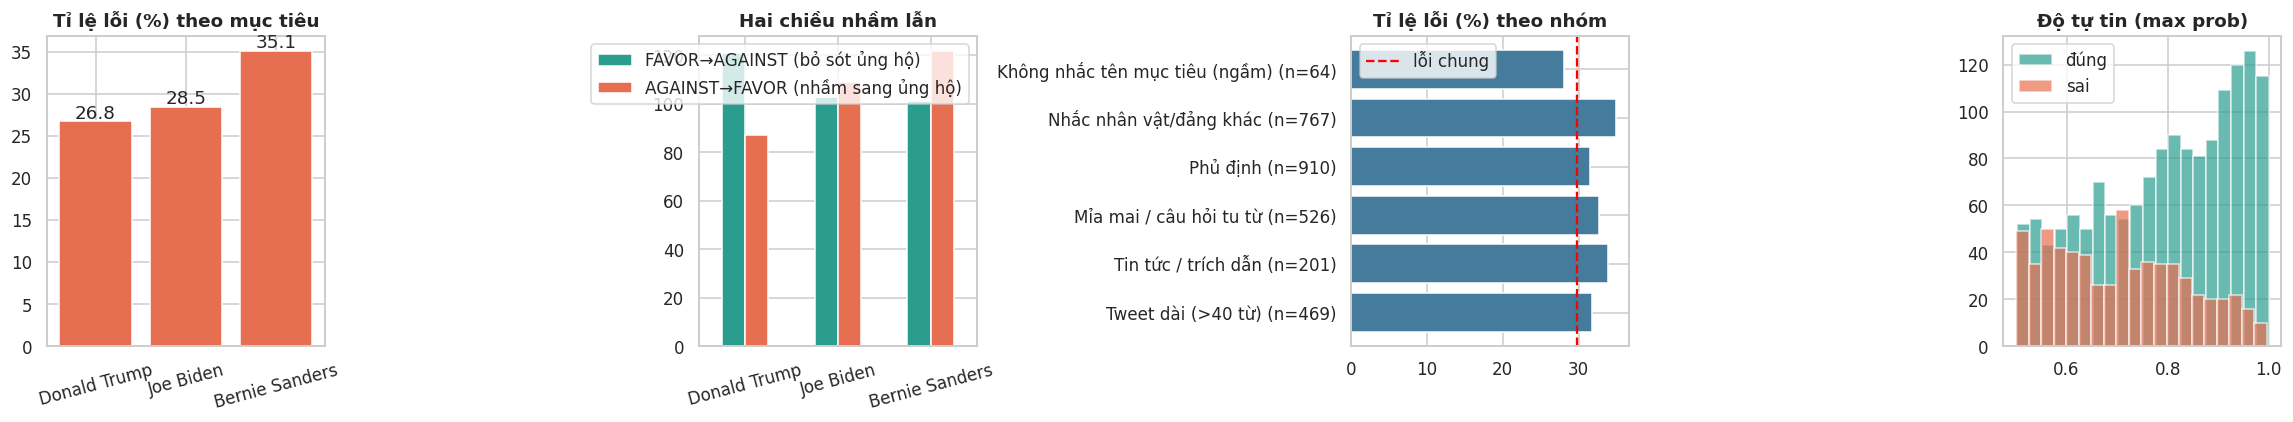

Thiên lệch dự đoán:


,% FAVOR thực tế,% FAVOR dự đoán
Donald Trump,45.3,40.9
Joe Biden,45.2,46.0
Bernie Sanders,54.0,57.3



>>> Thực tế FAVOR, đoán AGAINST  (tổng 325 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Joe Biden] conf=1.00 | Putting Jared Kushner In Charge Is Utter Madness Hey @JoeBiden and #HunterBiden, did you guys see this? #JaredKushner
   [Joe Biden] conf=0.98 | @potus Don, It seems like you could shoot someone dead right there in the #WhiteHouse #RoseGarden and get away with it now. Who cares about 5th ave! Who cares about the #Constitution #ByeByeGop #ImpeachedForever #GOP #DNC #DNC #democracy @T…
   [Donald Trump] conf=0.98 | #TuckerCarlson is a racist, propagandist who flaps his jaws for the highest bidder. "Any two-bit, dime-store, novelist can whip up a salacious melodrama in short order and disseminate it to a gullible flock of lemmings". Mark NC. #GOP #Trum…
   [Joe Biden] conf=0.98 | What 74 former #Biden staffers think about Tara Reades allegations | PBS NewsHour As a victim of #SexualAssault I can tell you details 45 years later. #TaraReade cant. #IBelieveJoe

>>> Thực tế AGAI

In [ ]:
error_report("Baseline TF-IDF+LR")

**Nhận xét:** *(điền sau khi chạy: loại lỗi chiếm nhiều nhất, thiên lệch dự đoán, nhóm nào lỗi cao hơn mức chung, ví dụ điển hình)*

### 7.2 Zero-shot BART-MNLI

PHÂN TÍCH LỖI: Zero-shot BART-MNLI   |   lỗi 633/2157 = 29.3%   |   Macro-F1 = 70.36


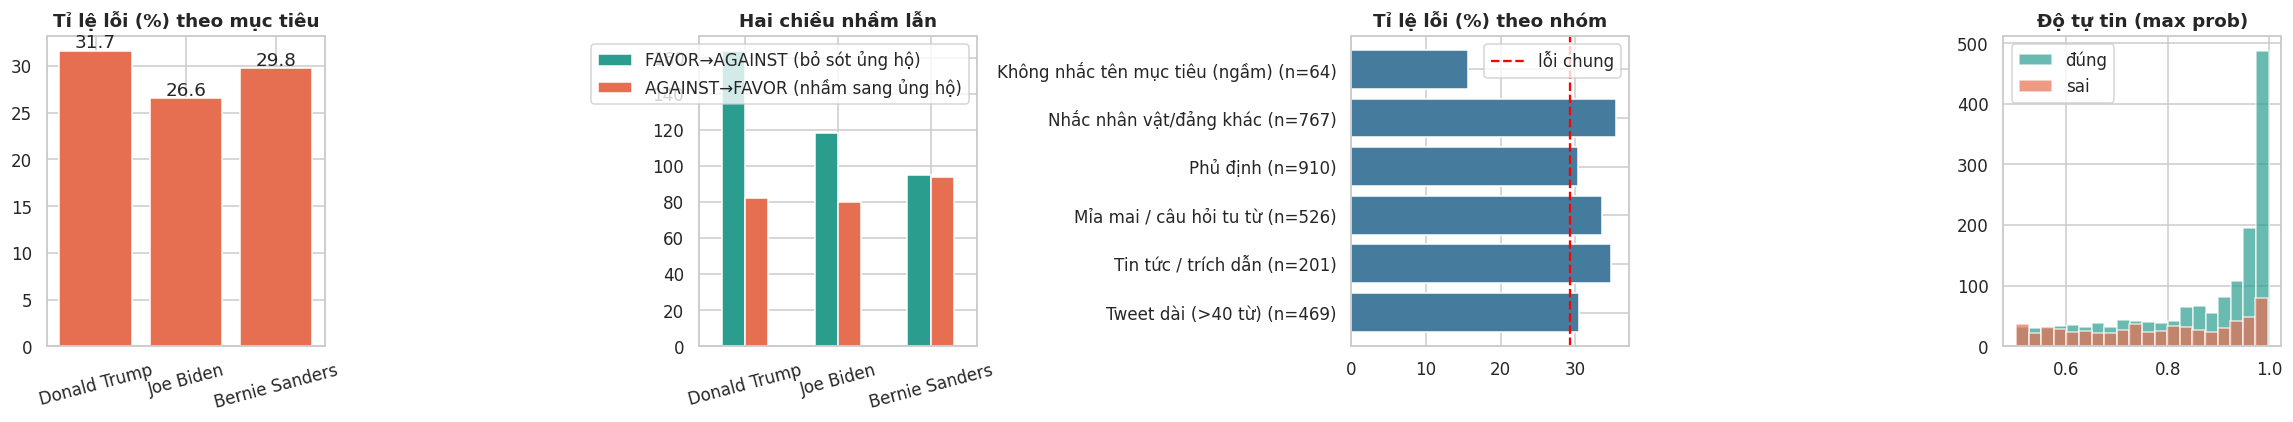

Thiên lệch dự đoán:


,% FAVOR thực tế,% FAVOR dự đoán
Donald Trump,45.3,34.7
Joe Biden,45.2,40.1
Bernie Sanders,54.0,53.9



>>> Thực tế FAVOR, đoán AGAINST  (tổng 377 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Donald Trump] conf=1.00 | 3) radical leftists at Twitter bragging about #shadowbanning conservatives, #Democrat operatives paid by the #Clinton #campaign engaging in #voterfraud, CNN employees admitting that the Trump-Russia story was a #fakenews ratings bonanza, an…
   [Bernie Sanders] conf=1.00 | These bots...their paid algorithm has been expanded to include any names appearing similar in addition to any names not appearing similar for the purpose of insulting the only viable candidate not owned & operated by the status quo #BernieS…
   [Donald Trump] conf=0.99 | #reiner wishes #Trump gone but HE IS likely to STAY N BE REELECTED The #Dems R turing into a mirror image of the BRITISH labor party steeped in ANTI-SEMITIC FILTH courtesy of #IlanOmar N #Rashidatlaib Who now cavorts with #farrakhan is ure …
   [Bernie Sanders] conf=0.99 | Seems that anti-socialist #Resisters are frequently female, r

In [ ]:
error_report("Zero-shot BART-MNLI")

**Nhận xét:** *(điền sau khi chạy: loại lỗi chiếm nhiều nhất, thiên lệch dự đoán, nhóm nào lỗi cao hơn mức chung, ví dụ điển hình)*

### 7.3 BERT-base

PHÂN TÍCH LỖI: BERT-base   |   lỗi 453/2157 = 21.0%   |   Macro-F1 = 78.94


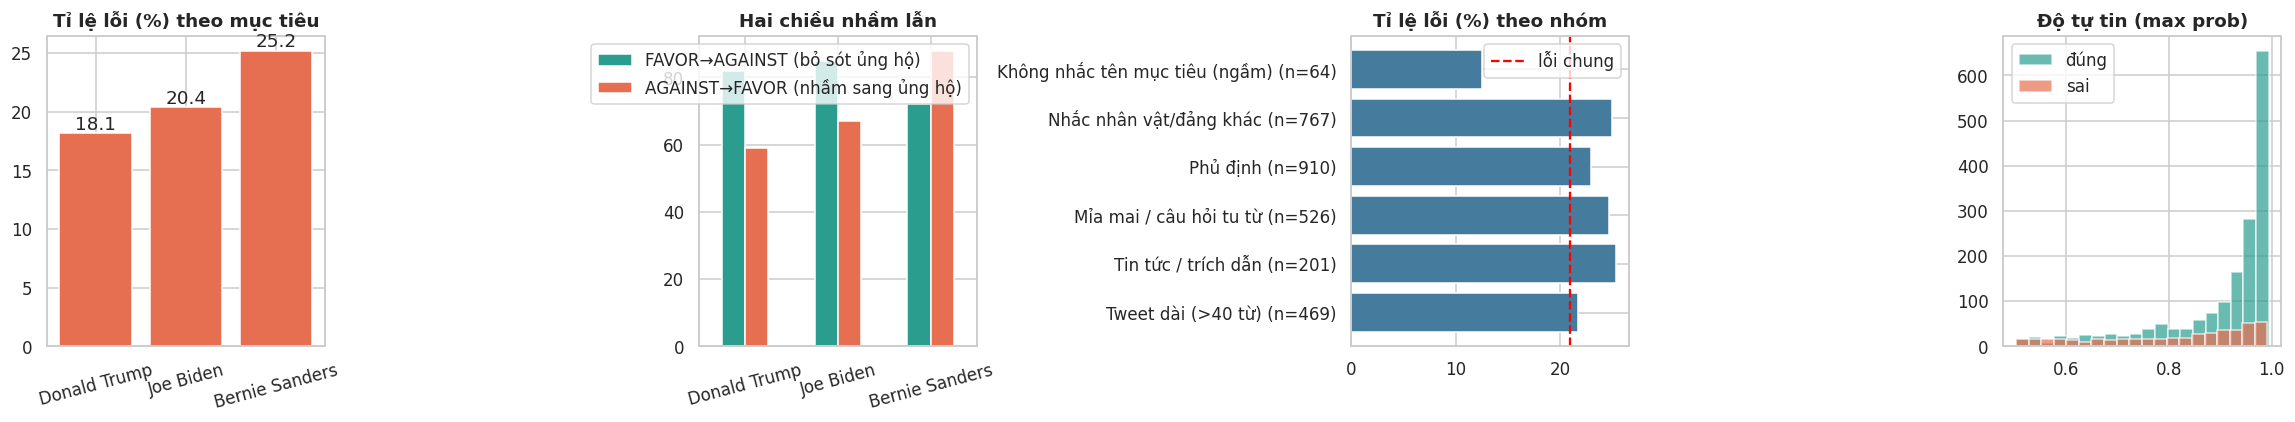

Thiên lệch dự đoán:


,% FAVOR thực tế,% FAVOR dự đoán
Donald Trump,45.3,42.3
Joe Biden,45.2,42.8
Bernie Sanders,54.0,56.5



>>> Thực tế FAVOR, đoán AGAINST  (tổng 239 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Joe Biden] conf=0.99 | Im watching a replay of the #DemocraticDebate, Joe Biden seems to being doing spectacularly well for someone that supposedly has dementia.
   [Donald Trump] conf=0.99 | Read the rough transcript of Trumps first phone call with Ukraine's Leader released by the White House.. #donaldtrump #trump #uspresident
   [Joe Biden] conf=0.99 | Joe Biden should be in an elderly home...He is utterly delusional.
   [Donald Trump] conf=0.98 | @BrownRbjr2002 #republican #crisis as one of many Republican who happens to be Black, there is an opportunity for the party to save GOP The soul of our nation as well as our historic past without question is a risk. Barney and Barman #Trump…

>>> Thực tế AGAINST, đoán FAVOR  (tổng 214 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Donald Trump] conf=0.99 | Sure can! #Trump Republican &amp; Democrat patriots unite! Proud to say My Twitter-feed is f

In [ ]:
error_report("BERT-base")

**Nhận xét:** *(điền sau khi chạy: loại lỗi chiếm nhiều nhất, thiên lệch dự đoán, nhóm nào lỗi cao hơn mức chung, ví dụ điển hình)*

### 7.4 RoBERTa-base

PHÂN TÍCH LỖI: RoBERTa-base   |   lỗi 407/2157 = 18.9%   |   Macro-F1 = 81.11


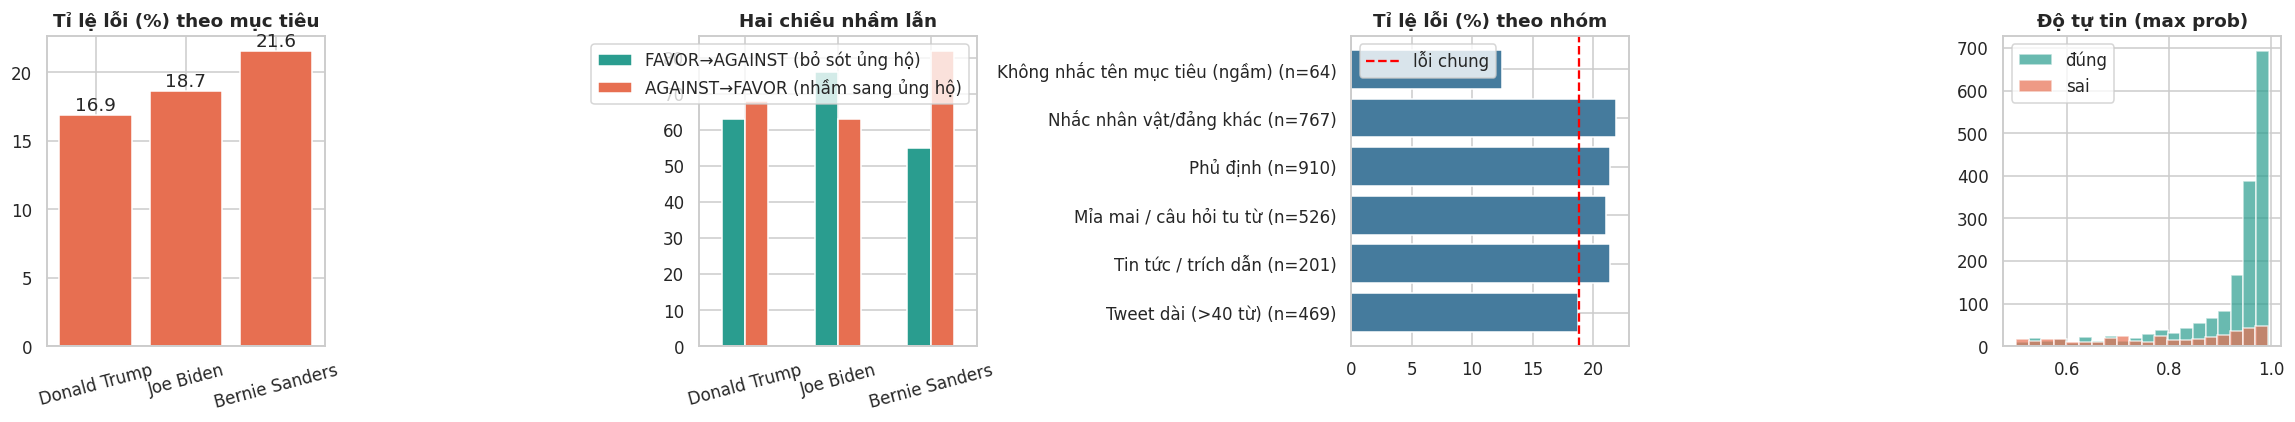

Thiên lệch dự đoán:


,% FAVOR thực tế,% FAVOR dự đoán
Donald Trump,45.3,45.9
Joe Biden,45.2,43.5
Bernie Sanders,54.0,58.3



>>> Thực tế FAVOR, đoán AGAINST  (tổng 194 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Donald Trump] conf=0.98 | It sounds like you are talking about the #Trump administration and #CorruptGOP. "past pattern of blatant deception &amp; actively trying to cover up the Coronavirus". This is the @GOP and Trump admin's M.O.
   [Donald Trump] conf=0.98 | Show us the evidence or there isn't any. This administration is led by a corrupt pathological liar and his team of #Republican cucks. I trust what we hear from Iran more than I trust what we hear from @realDonaldTrump and his administration…
   [Joe Biden] conf=0.98 | Joe Biden should be in an elderly home...He is utterly delusional.
   [Bernie Sanders] conf=0.98 | Sure Bernie are you really aware of the disaster going on in Illinois and how many are fleeing? Yet killing children. And doping everybody up is your priority. Awful

>>> Thực tế AGAINST, đoán FAVOR  (tổng 213 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Bernie Sanders] c

In [ ]:
error_report("RoBERTa-base")

**Nhận xét:** *(điền sau khi chạy: loại lỗi chiếm nhiều nhất, thiên lệch dự đoán, nhóm nào lỗi cao hơn mức chung, ví dụ điển hình)*

### 7.5 DistilBERT

PHÂN TÍCH LỖI: DistilBERT   |   lỗi 474/2157 = 22.0%   |   Macro-F1 = 77.92


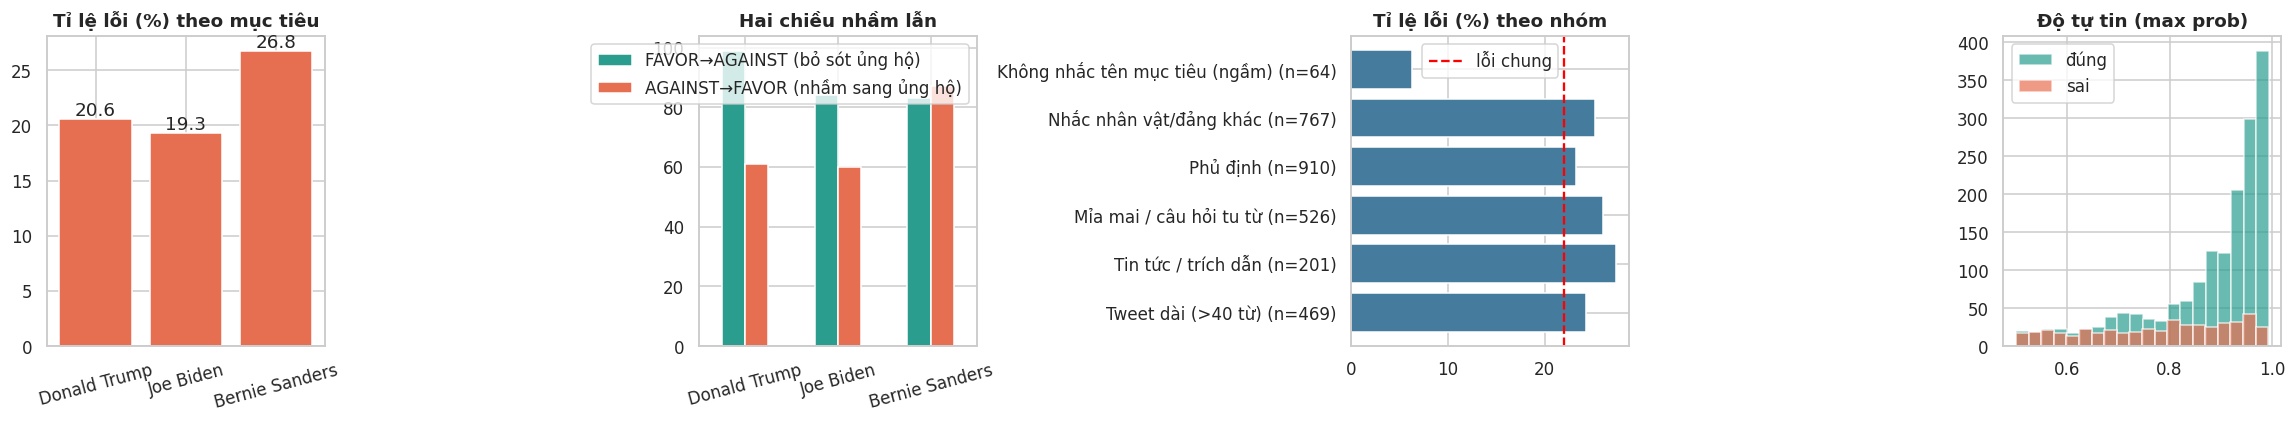

Thiên lệch dự đoán:


,% FAVOR thực tế,% FAVOR dự đoán
Donald Trump,45.3,40.4
Joe Biden,45.2,42.0
Bernie Sanders,54.0,54.6



>>> Thực tế FAVOR, đoán AGAINST  (tổng 266 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Donald Trump] conf=0.97 | When it comes to this madman, we often hear some fuck-up of his will be a game changer Please stop saying that term. Is overused and never achieved. #trump
   [Joe Biden] conf=0.97 | @JoeBiden is out of his element with this #Democrat #socialist party unless he has become socialist too$$, there wouldn't be a place for JFK in this party now
   [Donald Trump] conf=0.97 | Read the rough transcript of Trumps first phone call with Ukraine's Leader released by the White House.. #donaldtrump #trump #uspresident
   [Joe Biden] conf=0.96 | #NewBluehand #Bluehand RT WhiteHouse: .USTradeRep Lighthizer on today's trade announcement: It has 3 partsagriculture, industrial tariffs, and digital trade . . . This will open up markets to over 7 BILLION dollars of those products. #JoeBi…

>>> Thực tế AGAINST, đoán FAVOR  (tổng 208 tweet) – 4 ví dụ sai với độ tự tin cao nhất:
   [Bernie Sa

In [ ]:
error_report("DistilBERT")

**Nhận xét:** *(điền sau khi chạy: loại lỗi chiếm nhiều nhất, thiên lệch dự đoán, nhóm nào lỗi cao hơn mức chung, ví dụ điển hình)*

### 7.6 So sánh lỗi giữa các mô hình — có mắc cùng loại lỗi không?

,Baseline TF-IDF+LR,Zero-shot BART-MNLI,BERT-base,RoBERTa-base,DistilBERT
Không nhắc tên mục tiêu (ngầm),28.1,15.6,12.5,12.5,6.2
Nhắc nhân vật/đảng khác,34.9,35.5,25.0,21.9,25.2
Phủ định,31.5,30.3,23.0,21.4,23.2
Mỉa mai / câu hỏi tu từ,32.7,33.7,24.7,21.1,26.0
Tin tức / trích dẫn,33.8,34.8,25.4,21.4,27.4
Tweet dài (>40 từ),31.8,30.5,21.7,18.8,24.3
TOÀN BỘ,29.8,29.3,21.0,18.9,22.0


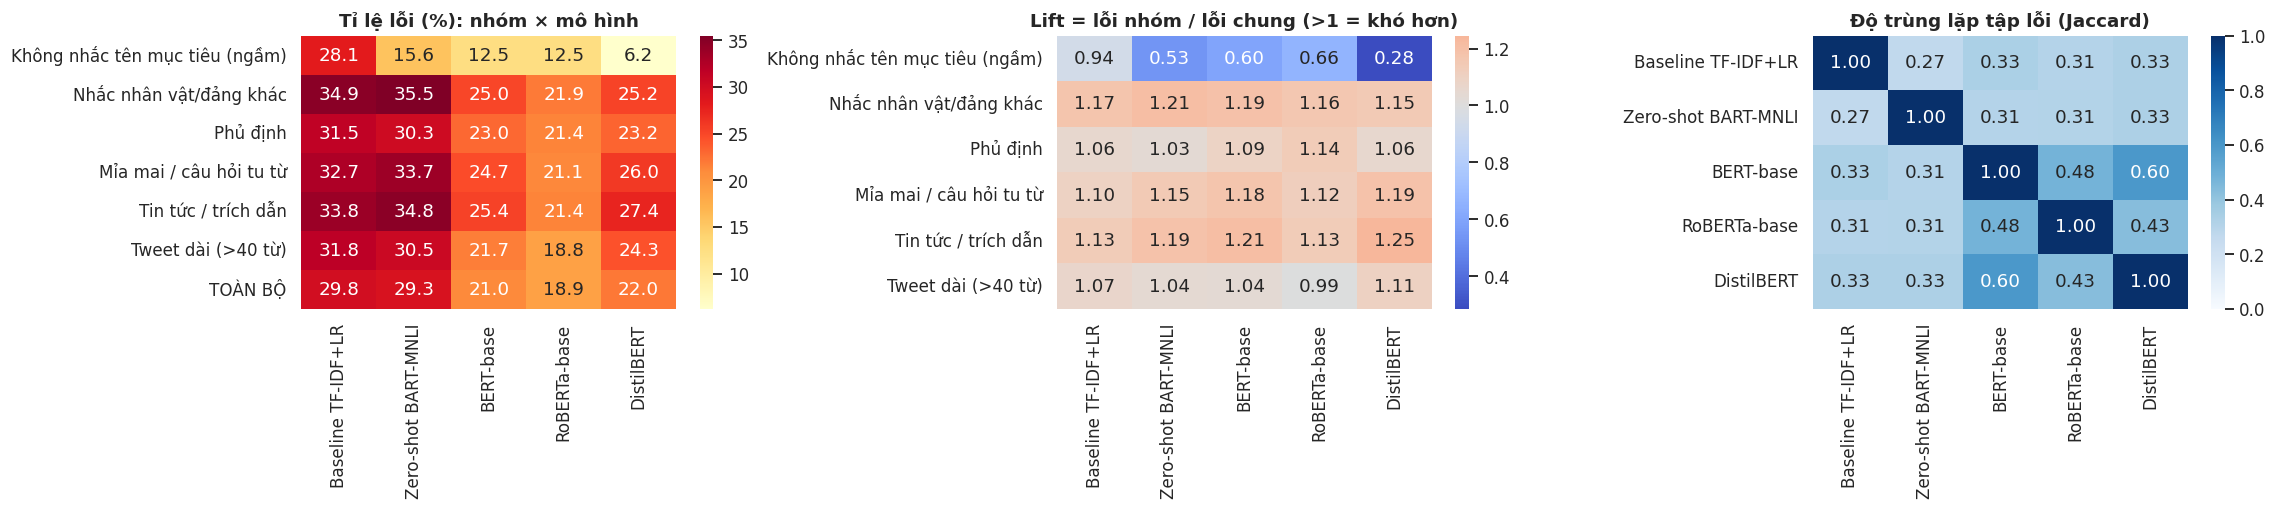

Tương quan 'hồ sơ lỗi theo nhóm' giữa 3 kiến trúc fine-tune (gần 1 = mắc cùng kiểu lỗi):


,BERT-base,RoBERTa-base,DistilBERT
BERT-base,1.00,0.98,0.98
RoBERTa-base,0.98,1.00,0.95
DistilBERT,0.98,0.95,1.00


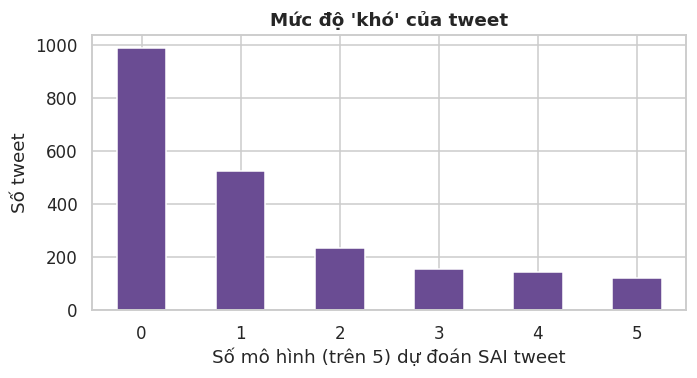

Tweet mà CẢ 3 kiến trúc fine-tune cùng sai: 236 (10.9%) | cả 5 mô hình cùng sai: 119

Ví dụ tweet khó (cả 3 kiến trúc fine-tune cùng sai):
  [Bernie Sanders] thực tế=FAVOR   | But you endorsed the guy who told everyone that it was safe to vote in person just a couple of weeks ago and again this week. Your candidate is #NotFitToLead. #BernieSanders is the one saying if you dont have mail in ballots stay home.
  [Bernie Sanders] thực tế=AGAINST | An example I shared with my 11 y/o daughter to explain walk the talk #Integrity #Bernie
  [Joe Biden] thực tế=AGAINST | @seanhannity look up 107-296 it's public record @JoeBiden @HillaryClinton all voted for it. FOR EVERYBODY FIGHTING ABOUT THE DETAINMENT OF CHILDREN SKIP TO 107-296 116-2205 ITS PUBLIC RECORD AND A CONGRESS ISSUE WAS PASSED 02
  [Joe Biden] thực tế=FAVOR   | #DemocraticDebate Wow!!! Uncle Joe just whacked Gillibrand : Whats changed ? You running for President ...
  [Joe Biden] thực tế=AGAINST | Biden has a whole 80 people show u

In [ ]:
errs = pd.DataFrame({m: PRED[m] != yt for m in MODEL_ORDER})

# (1) tỉ lệ lỗi theo nhóm × mô hình
tab = pd.DataFrame({m: {c: (errs[m][tags[c].values].mean() * 100 if tags[c].sum() else np.nan) for c in CATS} for m in MODEL_ORDER})
tab.loc["TOÀN BỘ"] = errs.mean() * 100
display(tab.round(1))
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
sns.heatmap(tab.round(1), annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0]); axes[0].set_title("Tỉ lệ lỗi (%): nhóm × mô hình")

# (2) mức tăng lỗi so với lỗi chung (lift)
lift = tab.drop("TOÀN BỘ") / tab.loc["TOÀN BỘ"]
sns.heatmap(lift, annot=True, fmt=".2f", cmap="coolwarm", center=1, ax=axes[1]); axes[1].set_title("Lift = lỗi nhóm / lỗi chung (>1 = khó hơn)")

# (3) Jaccard giữa các tập lỗi
jac = pd.DataFrame([[(errs[a] & errs[b]).sum() / max((errs[a] | errs[b]).sum(), 1) for b in MODEL_ORDER] for a in MODEL_ORDER], index=MODEL_ORDER, columns=MODEL_ORDER)
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Blues", ax=axes[2], vmin=0, vmax=1); axes[2].set_title("Độ trùng lặp tập lỗi (Jaccard)")
plt.tight_layout(); plt.show()

ft_names = list(MODELS)
corr = lift[ft_names].corr().round(2)
print("Tương quan 'hồ sơ lỗi theo nhóm' giữa 3 kiến trúc fine-tune (gần 1 = mắc cùng kiểu lỗi):"); display(corr)

# (4) số mô hình cùng sai trên mỗi tweet
k = errs.sum(1)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
k.value_counts().sort_index().plot(kind="bar", ax=ax, color="#6a4c93", rot=0); ax.set_xlabel("Số mô hình (trên 5) dự đoán SAI tweet"); ax.set_ylabel("Số tweet")
ax.set_title("Mức độ 'khó' của tweet"); plt.tight_layout(); plt.show()
ft_all_wrong = errs[ft_names].all(1)
print(f"Tweet mà CẢ 3 kiến trúc fine-tune cùng sai: {ft_all_wrong.sum()} ({ft_all_wrong.mean() * 100:.1f}%) | cả 5 mô hình cùng sai: {(k == len(MODEL_ORDER)).sum()}")
print("\nVí dụ tweet khó (cả 3 kiến trúc fine-tune cùng sai):")
for _, r in te_all[ft_all_wrong.values].sample(min(8, int(ft_all_wrong.sum())), random_state=0).iterrows():
    print(f"  [{TARGET_NAME[r.target]}] thực tế={r.stance:7s} | {short(r.text)}")

### 7.7 Lỗi khi chuyển sang mục tiêu chưa từng thấy (cross-target)
So sánh **cùng một tweet** giữa mô hình in-target (đã thấy mục tiêu) và mô hình cross-target (chưa thấy): tweet nào *bị hỏng* khi chuyển mục tiêu và vì sao.

BERT-base: tỉ lệ (%) tweet theo trạng thái khi chuyển từ in-target sang cross-target:


col_0,Sai cả hai,Sai → đúng,Đúng cả hai,Đúng → SAI (bị hỏng)
target_name,,,,
Bernie Sanders,19.7,5.5,55.7,19.1
Donald Trump,12.1,6.0,52.6,29.2
Joe Biden,14.0,6.4,60.8,18.8


Thiên lệch dự đoán khi chưa thấy mục tiêu:


,% FAVOR thực tế,% FAVOR (in-target),% FAVOR (cross-target)
Donald Trump,45.3,42.3,62.7
Joe Biden,45.2,42.8,62.4
Bernie Sanders,54.0,56.5,42.7


,Lỗi in-target (%),Lỗi cross-target (%),Tăng
Không nhắc tên mục tiêu (ngầm),12.5,10.9,-1.6
Nhắc nhân vật/đảng khác,25.0,44.6,19.6
Phủ định,23.0,40.0,17.0
Mỉa mai / câu hỏi tu từ,24.7,44.5,19.8
Tin tức / trích dẫn,25.4,41.3,15.9
Tweet dài (>40 từ),21.7,40.5,18.8
TOÀN BỘ,21.0,37.6,16.6


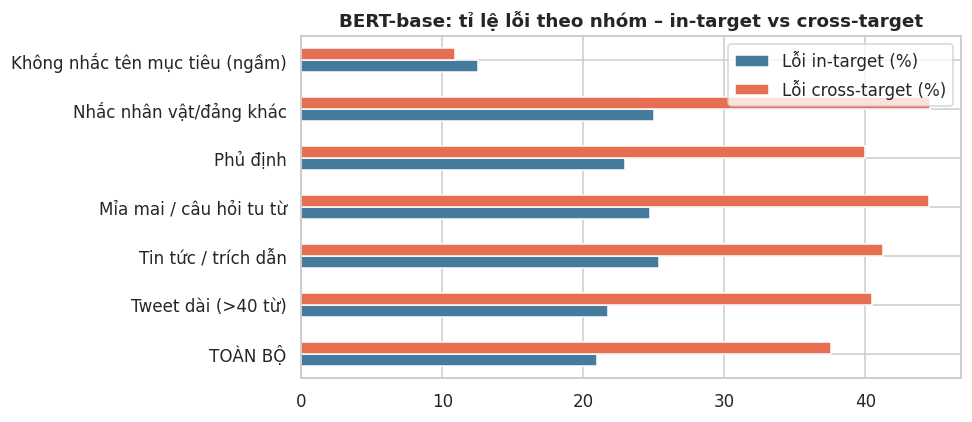


Ví dụ tweet bị hỏng khi chuyển sang mục tiêu mới (độ tự tin cao nhất):

--- Held-out: Donald Trump ---
   thực tế=AGAINST đoán=FAVOR   conf=0.98 | #NewBluehand #Bluehand On behalf of my family and my entire campaign, I want to wish everyone a happy, healthy, and prosperous Diwali. #Hillary #Trump
   thực tế=AGAINST đoán=FAVOR   conf=0.98 | #NewBluehand #Bluehand RT realDonaldTrump: I am thrilled to announce that in the second quarter of this year, the U.S. Economy grew at the amazing rate of 4.1%! #POTUS
   thực tế=AGAINST đoán=FAVOR   conf=0.98 | @DonWilliamson3 Plz follow back, #Trump #VotersUnite, country over party, equality, liberty, truth, justice. Together we can vote Trump out! Thank you, Susan

--- Held-out: Joe Biden ---
   thực tế=AGAINST đoán=FAVOR   conf=0.95 | Cuomo is responsible for massive reduction in hospital beds and is still pursuing Medicaid cuts. Corporate media loves those who serve their corporate lords, hence theyre marking Cuomo look like a hero. #CNNisTrash

In [ ]:
arch = CROSS_MODELS[0]
cross_p = np.full(len(te_all), np.nan)
for held in TARGETS:
    cross_p[(te_all.target == held).values] = cross_results[arch][held][SEEDS[0]]["test_probs"]
cross_pred = (cross_p >= .5).astype(int); in_pred = PRED[arch]
c_err, i_err = cross_pred != yt, in_pred != yt

flip = np.select([~i_err & ~c_err, ~i_err & c_err, i_err & ~c_err, i_err & c_err],
                 ["Đúng cả hai", "Đúng → SAI (bị hỏng)", "Sai → đúng", "Sai cả hai"],
                 default="")
ft = pd.crosstab(te_all.target_name, flip, normalize="index").mul(100).round(1)
print(f"{arch}: tỉ lệ (%) tweet theo trạng thái khi chuyển từ in-target sang cross-target:"); display(ft)

bias = pd.DataFrame({"% FAVOR thực tế": [yt[(te_all.target == t).values].mean() * 100 for t in TARGETS],
                     "% FAVOR (in-target)": [in_pred[(te_all.target == t).values].mean() * 100 for t in TARGETS],
                     "% FAVOR (cross-target)": [cross_pred[(te_all.target == t).values].mean() * 100 for t in TARGETS]},
                    index=[TARGET_NAME[t] for t in TARGETS]).round(1)
print("Thiên lệch dự đoán khi chưa thấy mục tiêu:"); display(bias)

tab_c = pd.DataFrame({"Lỗi in-target (%)": {c: i_err[tags[c].values].mean() * 100 for c in CATS},
                      "Lỗi cross-target (%)": {c: c_err[tags[c].values].mean() * 100 for c in CATS}})
tab_c.loc["TOÀN BỘ"] = [i_err.mean() * 100, c_err.mean() * 100]; tab_c["Tăng"] = tab_c.iloc[:, 1] - tab_c.iloc[:, 0]
display(tab_c.round(1))
fig, ax = plt.subplots(figsize=(9, 4)); tab_c[["Lỗi in-target (%)", "Lỗi cross-target (%)"]].iloc[::-1].plot(kind="barh", ax=ax, color=["#457b9d", "#e76f51"])
ax.set_title(f"{arch}: tỉ lệ lỗi theo nhóm – in-target vs cross-target"); plt.tight_layout(); plt.show()

broken = te_all.assign(true=np.where(yt == 1, "FAVOR", "AGAINST"), cross=np.where(cross_pred == 1, "FAVOR", "AGAINST"), conf=np.abs(cross_p - .5) * 2)[flip == "Đúng → SAI (bị hỏng)"]
print("\nVí dụ tweet bị hỏng khi chuyển sang mục tiêu mới (độ tự tin cao nhất):")
for t in TARGETS:
    print(f"\n--- Held-out: {TARGET_NAME[t]} ---")
    for _, r in broken[broken.target == t].sort_values("conf", ascending=False).head(3).iterrows():
        print(f"   thực tế={r.true:7s} đoán={r.cross:7s} conf={r.conf:.2f} | {short(r.text)}")

# 8. Demo Gradio
Nạp **kiến trúc tốt nhất** (Macro-F1 trung bình cao nhất trong 3 kiến trúc fine-tune; trọng số là lần chạy có VAL tốt nhất của kiến trúc đó) và đặt cạnh baseline TF-IDF+LR để thấy khác biệt khi **đổi mục tiêu** với cùng một tweet.

In [ ]:
import gradio as gr
best_arch = mean_t.loc[list(MODELS), "Fmacro"].idxmax()
best_dir = MODEL_DIR / (TAG + "_" + best_arch)
print("Kiến trúc tốt nhất:", best_arch, "| Fmacro trung bình =", round(mean_t.loc[best_arch, "Fmacro"], 2), "| thư mục:", best_dir)
assert best_dir.exists(), "Chưa có trọng số đã lưu – chạy lại ô 5C-1 (xóa file cache .pkl của kiến trúc này nếu cần)."

tok_d = AutoTokenizer.from_pretrained(best_dir)
mdl_d = AutoModelForSequenceClassification.from_pretrained(best_dir).to(DEVICE).eval()

@torch.no_grad()
def predict(text, target_name):
    if not text or not text.strip():
        return None, None
    enc = tok_d(target_name, clean_transformer(text), truncation="only_second", max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
    p = torch.softmax(mdl_d(**enc).logits.float(), -1)[0].cpu().numpy()
    pb = float(base_final.predict_proba([clean_tfidf(text)])[0, 1])
    return {"FAVOR": float(p[1]), "AGAINST": float(p[0])}, {"FAVOR": pb, "AGAINST": 1 - pb}

examples = [[r.text, r.target_name] for r in te_all.sample(5, random_state=3).itertuples()]
demo = gr.Interface(
    fn=predict,
    inputs=[gr.Textbox(lines=5, label="Tweet (tiếng Anh)", placeholder="Dán nội dung tweet vào đây..."),
            gr.Dropdown(list(TARGET_NAME.values()), value="Donald Trump", label="Mục tiêu cần xác định lập trường")],
    outputs=[gr.Label(num_top_classes=2, label=f"Mô hình tốt nhất: {best_arch} (biết mục tiêu)"),
             gr.Label(num_top_classes=2, label="Baseline TF-IDF + LR (không biết mục tiêu)")],
    examples=examples,
    title="🗳️ P-Stance – Phát hiện lập trường chính trị",
    description="Nhập tweet và chọn nhân vật. Thử đổi mục tiêu với cùng một tweet để thấy mô hình target-aware thay đổi dự đoán, còn baseline thì không.",
)
demo.launch(share=True, debug=False)

Kiến trúc tốt nhất: RoBERTa-base | Fmacro trung bình = 80.44 | thư mục: /content/drive/MyDrive/DO_AN_XLNNTN/models/f_RoBERTa-base


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c07c68744f99bbe0f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# File app.py độc lập để nộp kèm (chạy: python app.py, đặt MODEL_DIR trỏ tới thư mục mô hình đã lưu)
APP = r"""
import re, html, sys, torch, gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification
MODEL_DIR = sys.argv[1] if len(sys.argv) > 1 else "best_model"
TARGETS = ["Donald Trump", "Joe Biden", "Bernie Sanders"]
tok = AutoTokenizer.from_pretrained(MODEL_DIR)
mdl = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).eval()

def clean(t):
    t = html.unescape(t)
    t = re.sub(r"https?://\S+|www\.\S+", "url", t)
    t = re.sub(r"@\w+", "@user", t)
    t = re.sub(r"#(\w+)", lambda m: re.sub(r"(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])", " ", m.group(1)), t)
    return re.sub(r"\s+", " ", t).strip()

@torch.no_grad()
def predict(text, target):
    enc = tok(target, clean(text), truncation="only_second", max_length=128, return_tensors="pt")
    p = torch.softmax(mdl(**enc).logits, -1)[0]
    return {"FAVOR": float(p[1]), "AGAINST": float(p[0])}

gr.Interface(predict, [gr.Textbox(lines=5, label="Tweet"), gr.Dropdown(TARGETS, value=TARGETS[0], label="Mục tiêu")],
             gr.Label(num_top_classes=2), title="P-Stance Demo").launch()
"""
(OUT_DIR / "app.py").write_text(APP, encoding="utf-8")
print("Đã lưu", OUT_DIR / "app.py")

Đã lưu /content/drive/MyDrive/DO_AN_XLNNTN/outputs/app.py
